## What is Seaborn?
- A Python package for generating statistical graphics.
- It offers preset styles and color palettes, enabling the creation of complex, visually appealing charts with minimal code.
- Designed to make visualization a core part of data exploration and analysis.
- Its dataset-oriented plotting functions work seamlessly with Pandas DataFrames and NumPy arrays, performing semantic mapping and statistical aggregation to produce insightful plots.
- Built on top of Matplotlib, Seaborn complements rather than replaces it, utilizing Matplotlib for rendering behind the scenes.

In [473]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Why as `seaborn`?

- Michael Waskom, the library’s creator, named it after the *Seaborn McDougle* – statistical consulting firm, which was part of the company where he was working when he started developing the library.
- The word *seaborn* could suggest something *born of the sea*, metaphorically linking it to waves, patterns, and fluid data visualization techniques.


### Why as `sns`?

- It is a joke reference *Samuel Norman "Sam" Seaborn*, a fictional character portrayed by Rob Lowe on the television serial drama The West Wing.
- You can also think of it as *seaborn name space*.

## Seaborn can change appearance of Matplotlib figures

- While Matplotlib is highly customizable, it can be complex, as determining the right settings for an aesthetically pleasing plot can be challenging.  
- Seaborn simplifies this process by providing built-in themes and a high-level interface for adjusting the appearance of Matplotlib figures.  

### Setting the Default Seaborn Theme  

The recommended way to configure Seaborn's theme, scaling, and color palette is:

```python
sns.set_theme()
```

- If you simply call the `set_theme()`, you switch to seaborn defaults.
- We have 5 seaborn themes: `darkgrid`, `whitegrid`, `dark`, `white`, and `ticks`. The default theme is `darkgrid`.

This function updates Matplotlib's `rcParams` to apply Seaborn’s styling preferences.  
   - `rcParams` (runtime configuration parameters) are a set of global settings in Matplotlib that control the appearance of plots. 
   - These parameters define aspects such as figure size, colors, fonts, line styles, and more.  

Seaborn modifies `rcParams` to apply its own themes and styles, ensuring visually appealing plots with minimal effort.  


**Note:** `sns.set()` is *deprecated* and should no longer be used.

In [474]:
# You can view or modify Matplotlib's `rcParams` directly:
# print(plt.rcParams)

# You can change a specific `rcParam` (e.g., figure size)
plt.rcParams["figure.figsize"] = (6, 4.5)

## Scaling plot elements

A separate set of parameters control the scale of plot elements, which should let you use the same code to make plots that are suited for use in settings where larger or smaller plots are appropriate.

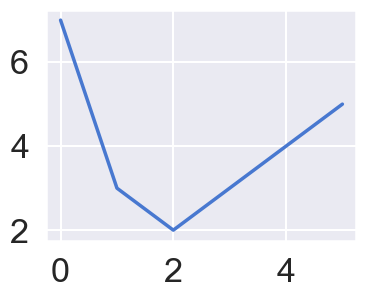

In [475]:
sns.set_theme(style="darkgrid", context="talk", palette="muted", font_scale=1.5, rc={"lines.linewidth": 2.5})

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot([7, 3, 2, 3, 4, 5]);

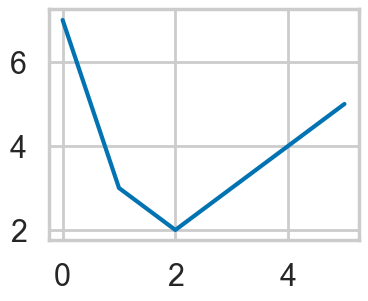

In [476]:
# Set style (options: 'darkgrid', 'whitegrid', 'dark', 'white', 'ticks') default: 'darkgrid'
sns.set_style("whitegrid")

# Set context (options: 'paper', 'notebook', 'talk', 'poster') default: 'notebook'
sns.set_context("poster")

# Set color theme (options: 'deep', 'muted', 'bright', 'colorblind') default: 'deep'
sns.set_palette("colorblind")  

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot([7, 3, 2, 3, 4, 5]);

In [477]:
def cosplot(n=10, flip=10):
    x = np.linspace(0, 10, 100)
    fig, ax = plt.subplots(figsize=(4, 3))
    for i in range(1, n + 1):
        ax.plot(x, np.cos(x + i * .5) * (n + 2 - i) * flip)

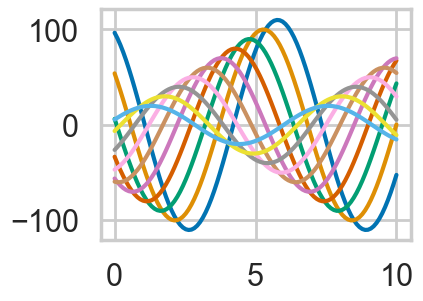

In [478]:
cosplot()

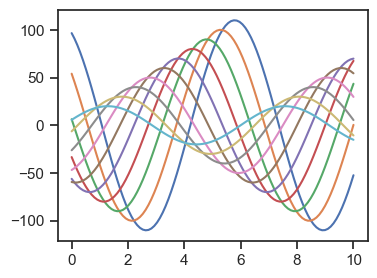

In [479]:
sns.set_theme(style="ticks")
cosplot()

## Removing axes spines

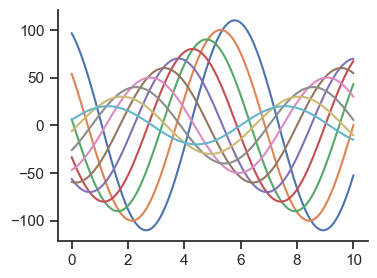

In [480]:
cosplot()
sns.despine()

Some plots benefit from offsetting the spines away from the data, which can also be done when calling `despine()`.
 
When the ticks don’t cover the whole range of the axis, the `trim` parameter will limit the range of the surviving spines.

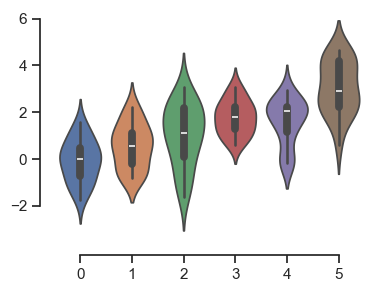

In [481]:
data = np.random.normal(size=(20, 6)) + np.arange(6) / 2

fig, ax = plt.subplots(figsize=(4, 3))
sns.violinplot(data=data)
sns.despine(offset=10, trim=True);

You can also control which spines are removed with additional arguments to `despine()`:

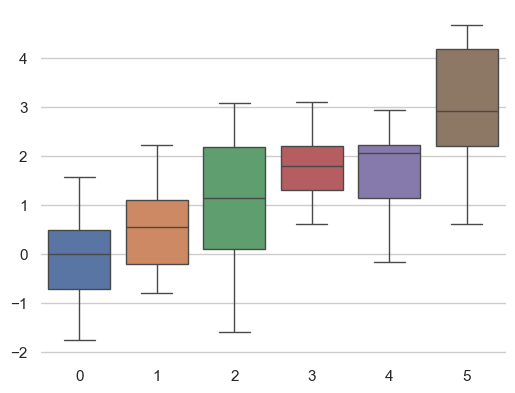

In [482]:
sns.set_style("whitegrid")
sns.boxplot(data=data, palette="deep")
sns.despine(left=True, bottom=True)

## Temporarily setting figure style

You can use the `axes_style()` in a with statement to temporarily set plot parameters. 

This also allows you to make figures with differently-styled axes:

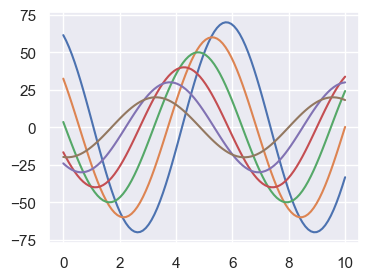

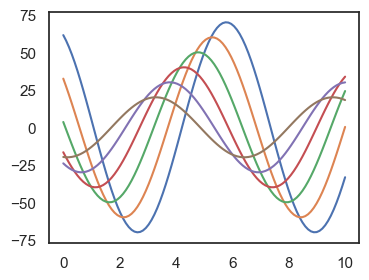

In [483]:
with sns.axes_style("darkgrid"):
    cosplot(6)

with sns.axes_style("white"):
    cosplot(6)

In [484]:
sns.set_style("white")

# Seaborn main plotting functions

### Figure-Level vs. Axes-Level Functions in Seaborn

#### 1. Figure-Level Functions: `relplot`, `displot`, `catplot`
- Create an **entire figure** with subplots automatically.
- Return a **FacetGrid** or similar object, not an `ax`.
- Support `col`, `row`, and `hue` for faceting.


#### 2. Axes-Level Functions: `scatterplot`, `lineplot`, etc.
- Work on a **specific Matplotlib Axes**.
- Require an explicit `ax` for embedding in figures.
- Return an `ax` object, modifiable with Matplotlib.

#### Relationship between Figure-Level Functions and Axes-Level Functions
`relplot` (relational)
- `scatterplot`
- `lineplot`

`displot` (distributions)
- `histplot`
- `kdeplot`
- `ecdfplot`
- `rugplot`

`catplot` (categorical)
- `stripplot`
- `swarmplot`
- `boxplot`
- `violinplot`
- `pointplot`
- `barplot`

#### Key Differences

| Feature            | Figure-Level (`sns.catplot()`, etc.) | Axes-Level (`sns.boxplot()`, etc.) |
|--------------------|----------------------------------|----------------------------------|
| Creates figure?    | ✅ Yes                           | ❌ No, needs `plt.subplots()` |
| Returns           | `FacetGrid`, `PairGrid`, etc.   | `Axes` object                 |
| Supports multiple subplots? | ✅ Yes (`col`, `row`, `hue`) | ❌ No, must use `plt.subplots()` |
| Places legend inside of `ax`? | ❌ No | ✅ Yes |


In [485]:
tips = sns.load_dataset("tips")
tips.sample(7)

,total_bill,tip,sex,smoker,day,time,size
91,22.49,3.50,Male,No,Fri,Dinner,2
189,23.10,4.00,Male,Yes,Sun,Dinner,3
60,20.29,3.21,Male,Yes,Sat,Dinner,2
120,11.69,2.31,Male,No,Thur,Lunch,2
101,15.38,3.00,Female,Yes,Fri,Dinner,2
3,23.68,3.31,Male,No,Sun,Dinner,2
69,15.01,2.09,Male,Yes,Sat,Dinner,2


In [486]:
tips.describe().style.format("{:.1f}")

,total_bill,tip,size
count,244.0,244.0,244.0
mean,19.8,3.0,2.6
std,8.9,1.4,1.0
min,3.1,1.0,1.0
25%,13.3,2.0,2.0
50%,17.8,2.9,2.0
75%,24.1,3.6,3.0
max,50.8,10.0,6.0


In [487]:
tips.select_dtypes(include=['object', 'category']).describe()

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [488]:
tips[tips.select_dtypes('object').columns] = tips.select_dtypes('object').astype('category')
tips.select_dtypes('category').apply(lambda col: list(col.cat.categories))

sex              [Male, Female]
smoker                [Yes, No]
day       [Thur, Fri, Sat, Sun]
time            [Lunch, Dinner]
dtype: object

# Relational plots

## `scatterplot` and `relplot`

- The relationship between `x` and `y` can be shown for different subsets of the data using the `hue`, `size`, and `style` parameters.
- These parameters control what visual semantics are used to identify the different subsets.

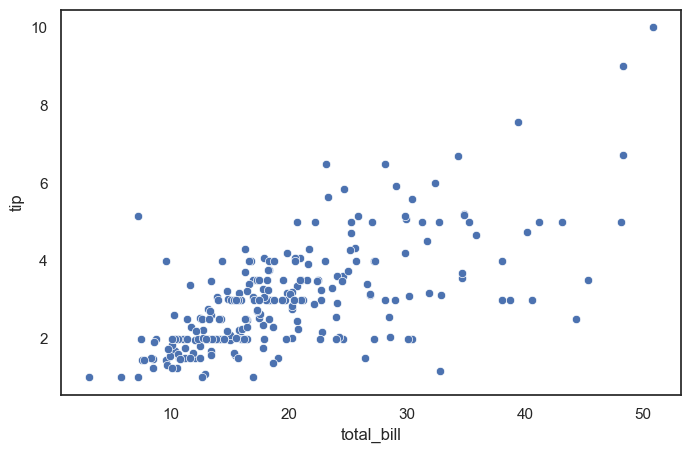

In [489]:
# plt.figure(figsize=(8, 5))

fig, ax = plt.subplots()
fig.set_size_inches(8, 5)

sns.scatterplot(data=tips, x="total_bill", y="tip");

Assigning a variable to hue will map its levels to the color of the points:

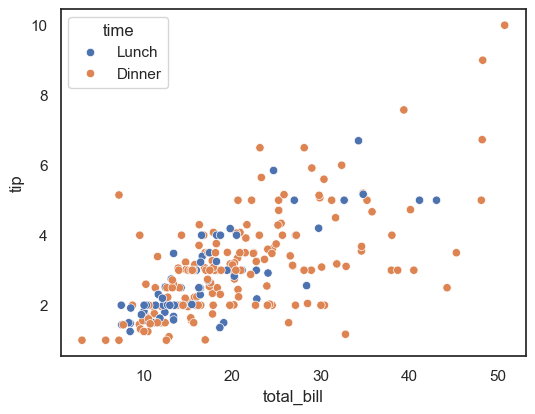

In [490]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time");

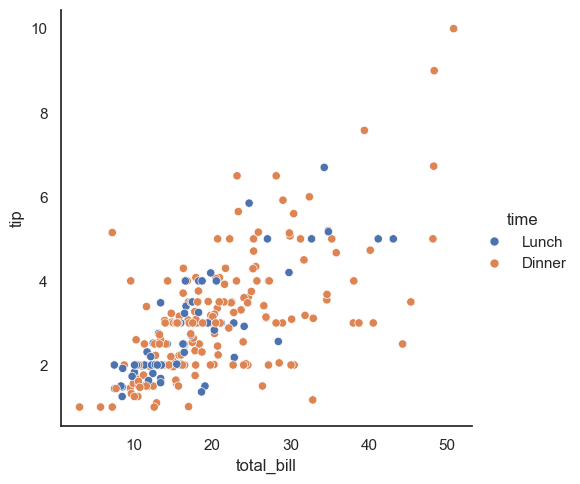

In [491]:
# sns.relplot(data=tips, x="total_bill", y="tip", hue="time")
sns.relplot(data=tips, x="total_bill", y="tip", hue="time", kind="scatter");

Assigning the same variable to style will also vary the markers and create a more accessible plot:

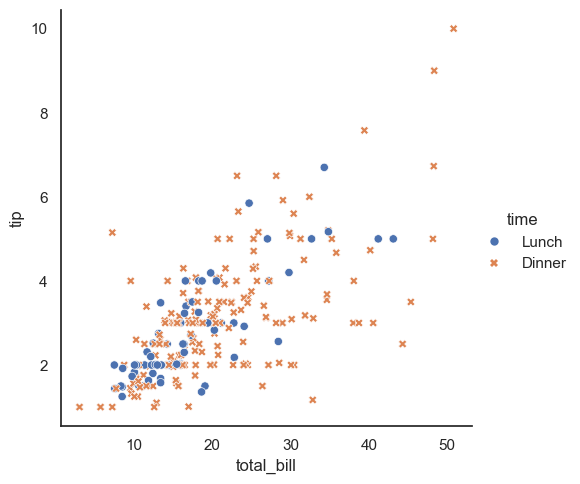

In [492]:
sns.relplot(data=tips, x="total_bill", y="tip", hue="time", style="time");

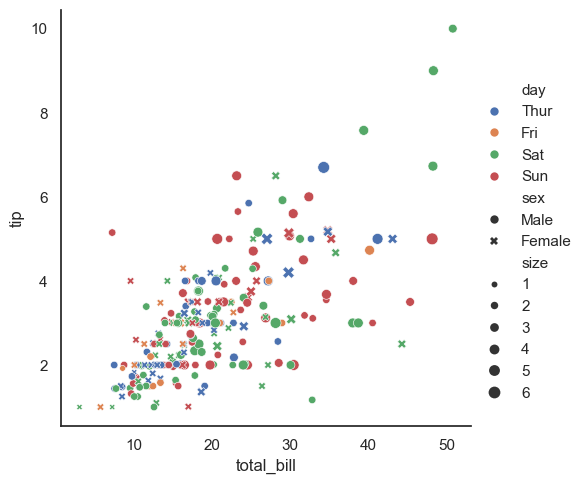

In [493]:
sns.relplot(data=tips, x="total_bill", y="tip", hue="day", style="sex", size="size", palette="deep");

Assigning hue and style to different variables will vary colors and markers independently:

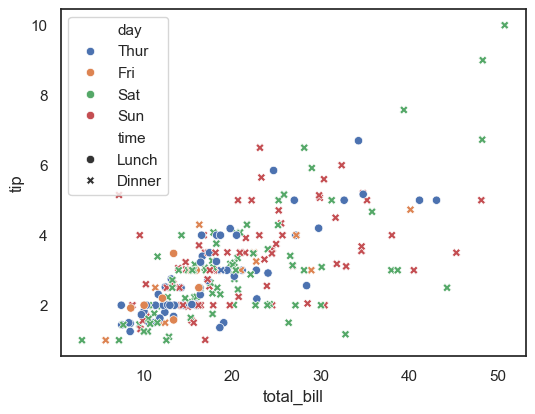

In [494]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="day", style="time");

If the variable assigned to hue is numeric, the semantic mapping will be quantitative and use a different default palette:

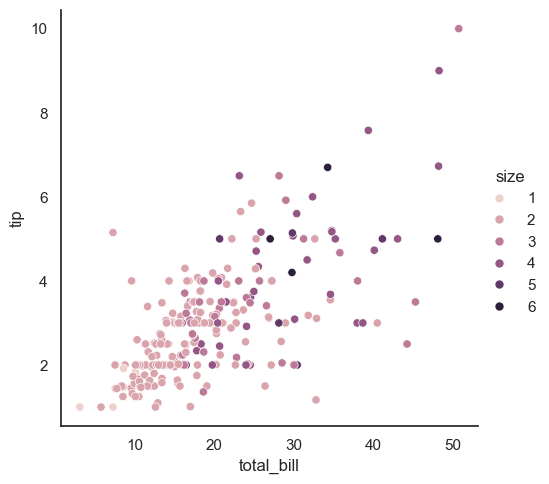

In [495]:
sns.relplot(data=tips, x="total_bill", y="tip", hue="size");

Pass the name of a categorical palette or explicit colors (as a Python list of dictionary) to force categorical mapping of the hue variable:

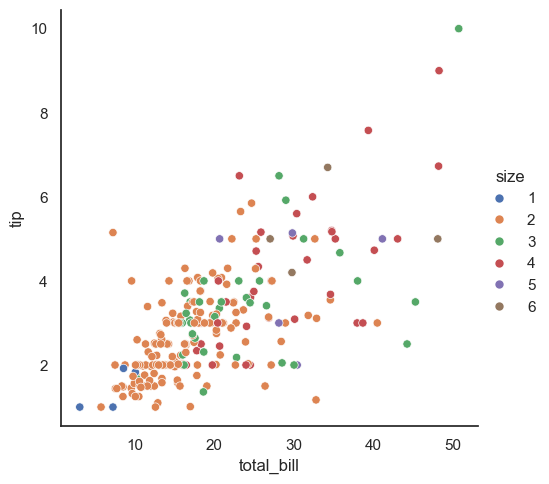

In [496]:
sns.relplot(data=tips, x="total_bill", y="tip", hue="size", palette="deep");

If there are a large number of unique numeric values, the legend will show a representative, evenly-spaced set:

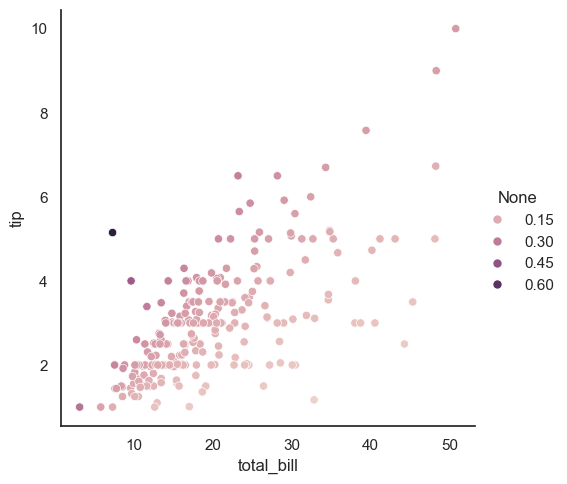

In [497]:
tip_rate = tips["tip"] / tips["total_bill"]
sns.relplot(data=tips, x="total_bill", y="tip", hue=tip_rate);

Control the specific markers used to map the style variable by passing a Python list or dictionary of marker codes:

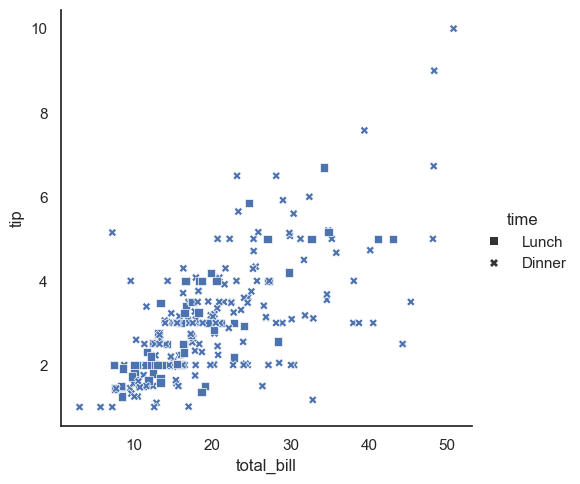

In [498]:
markers = {"Lunch": "s", "Dinner": "X"}
sns.relplot(data=tips, x="total_bill", y="tip", style="time", markers=markers);

`relplot()` allows grouping within additional categorical variables, and plotting them across multiple subplots.

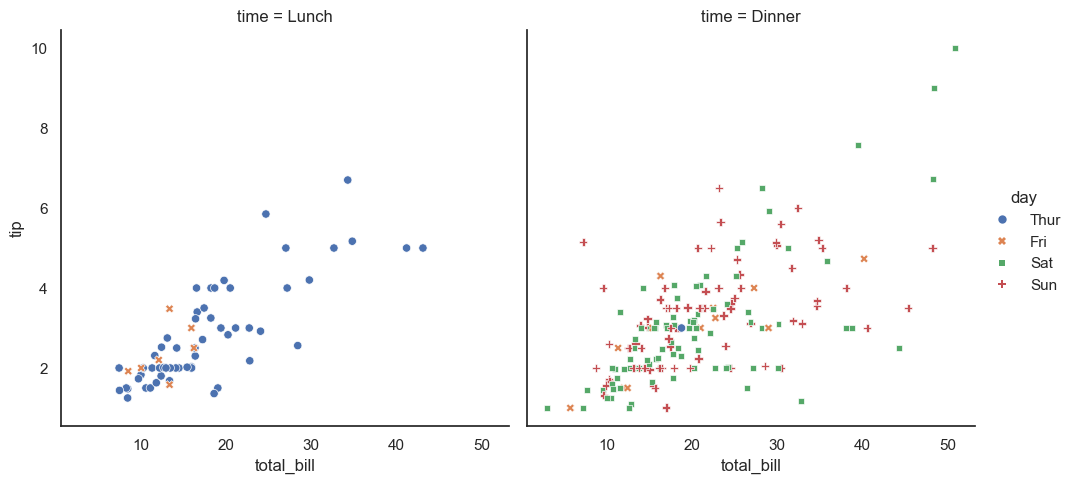

In [499]:
sns.relplot(
    data=tips, x="total_bill", y="tip",
    col="time", hue="day", style="day",
    kind="scatter"
);

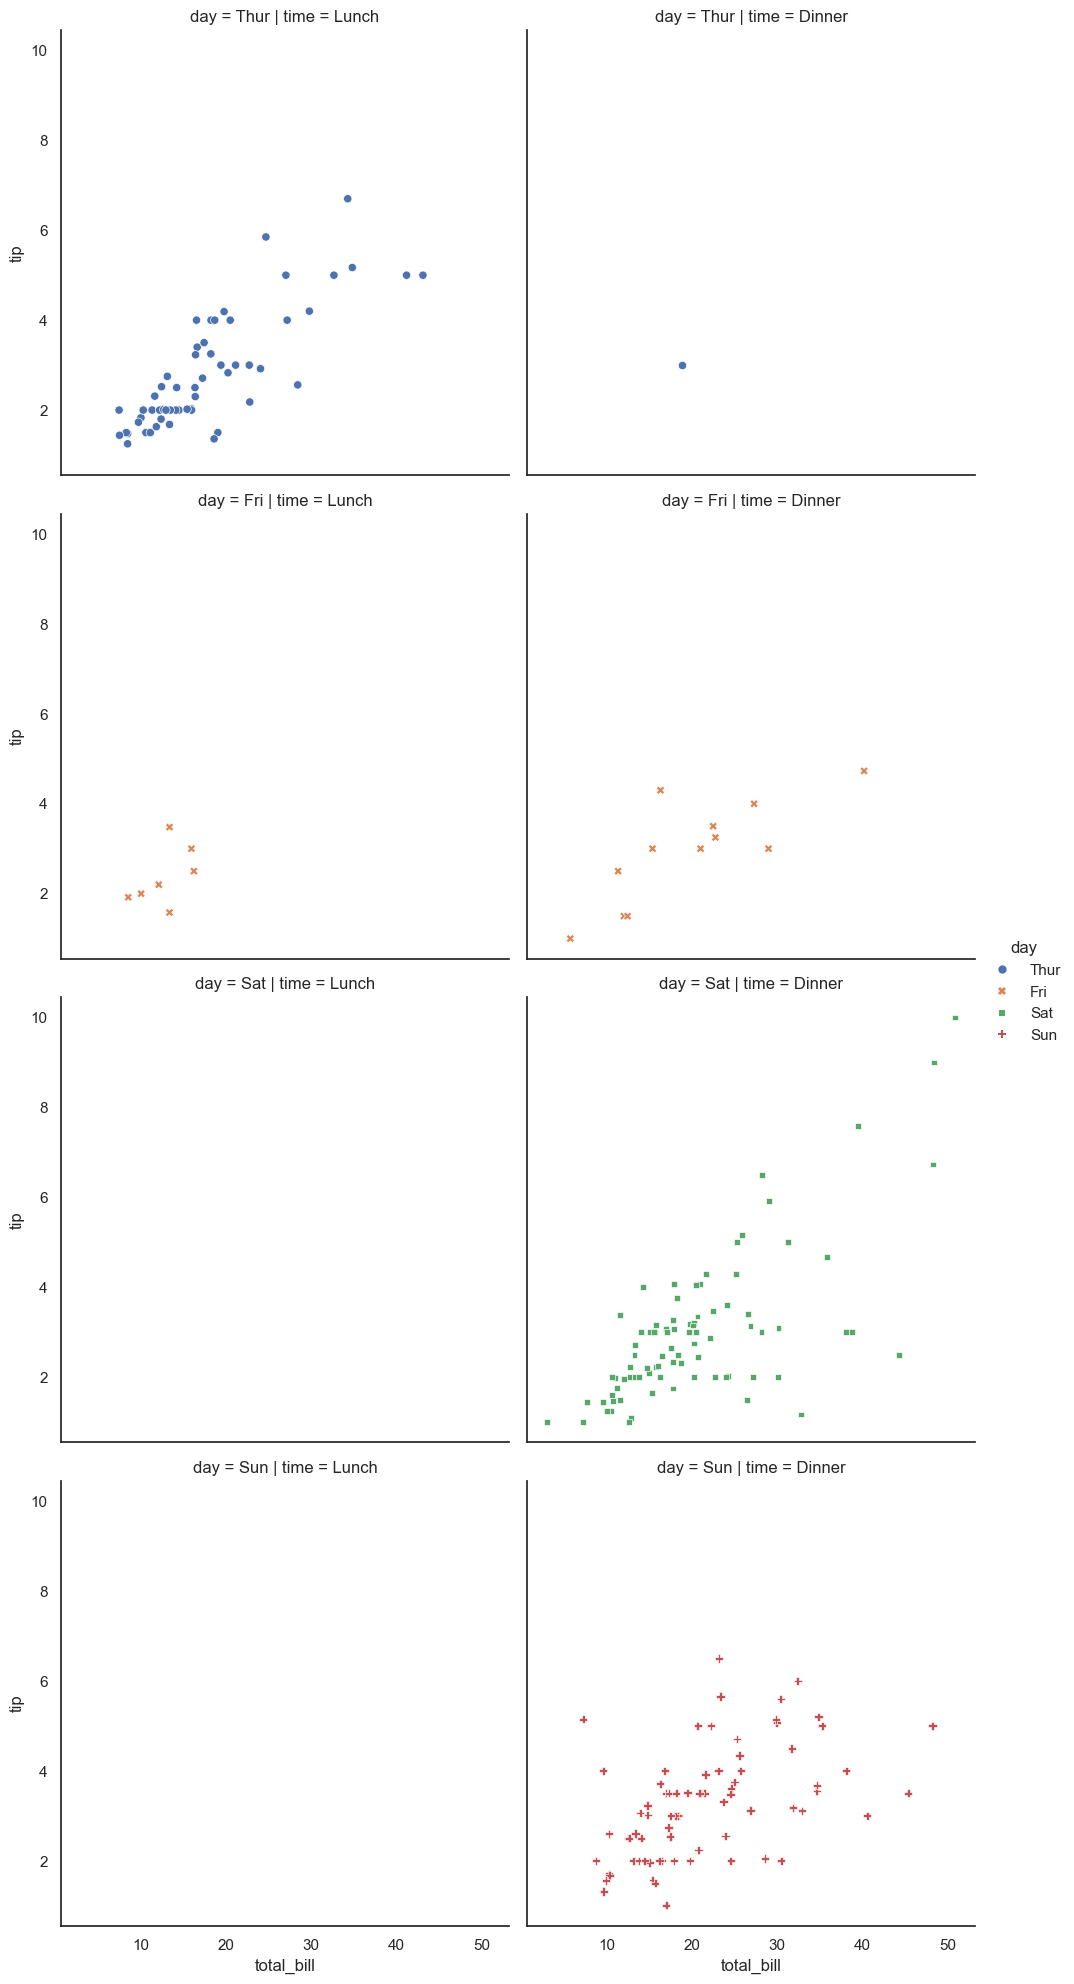

In [500]:
sns.relplot(
    data=tips, x="total_bill", y="tip",
    row="day",  col="time", hue="day", style="day",
    kind="scatter"
);

## `lineplot` and `relplot`

In [501]:
flights = sns.load_dataset("flights")
flights.sample(7)

,year,month,passengers
134,1960,Mar,419
122,1959,Mar,406
108,1958,Jan,340
48,1953,Jan,196
61,1954,Feb,188
126,1959,Jul,548
114,1958,Jul,491


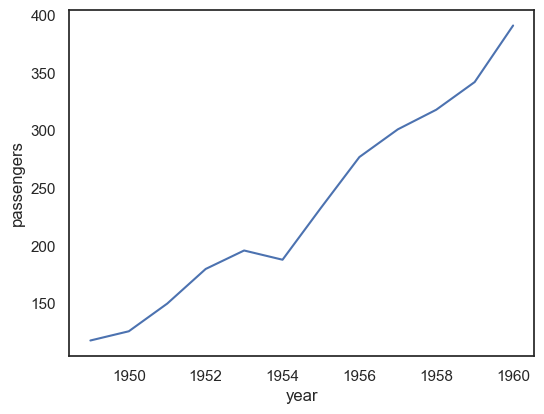

In [502]:
feb_flights = flights[flights["month"] == "Feb"]
sns.lineplot(data=feb_flights, x="year", y="passengers");

Let's pivot the dataframe to a wide-form representation:

In [503]:
flights_wide = flights.pivot(index="year", columns="month", values="passengers")
flights_wide.head()

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
1949,112,118,132,129,121,135,148,148,136,119,104,118
1950,115,126,141,135,125,149,170,170,158,133,114,140
1951,145,150,178,163,172,178,199,199,184,162,146,166
1952,171,180,193,181,183,218,230,242,209,191,172,194
1953,196,196,236,235,229,243,264,272,237,211,180,201


To plot a single vector, pass it to data. If the vector is a `pandas.Series`, it will be plotted against its index:

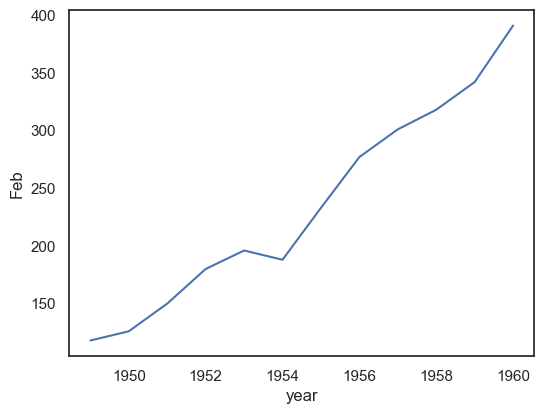

In [504]:
sns.lineplot(data=flights_wide["Feb"]);

Passing the entire wide-form dataset to data plots a separate line for each column:

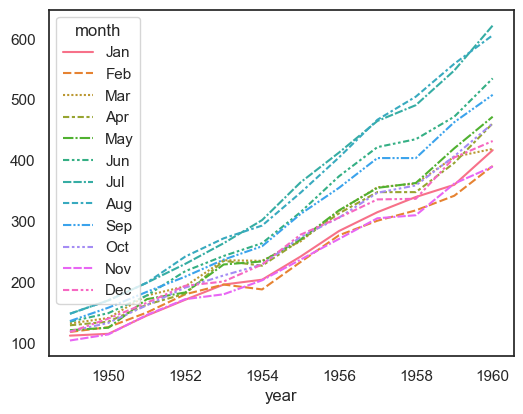

In [505]:
sns.lineplot(data=flights_wide);

#### Placing the Legend Outside the Axes

In many cases, you may want to position the legend outside the plot area to avoid overlap with the data. This can be achieved in two ways:

1. **Using Matplotlib**  
   The `bbox_to_anchor` parameter in `plt.legend()` allows you to move the legend outside the axes. It specifies a bounding box where the legend is positioned, with `loc` determining which part of the legend box aligns with the specified coordinates. 
   
   For example, setting `bbox_to_anchor=(1.05, 1)` places the upper-left corner of the legend at `(1.05, 1)`, slightly outside the plot area. 
   
   Additionally, `frameon=False` can be used to remove the border around the legend.

2. **Using Seaborn**  
   When using figure-level functions like `relplot`, `catplot`, or `lmplot`, seaborn automatically places the legend outside the axes. This makes it convenient for handling legends without manual adjustments.


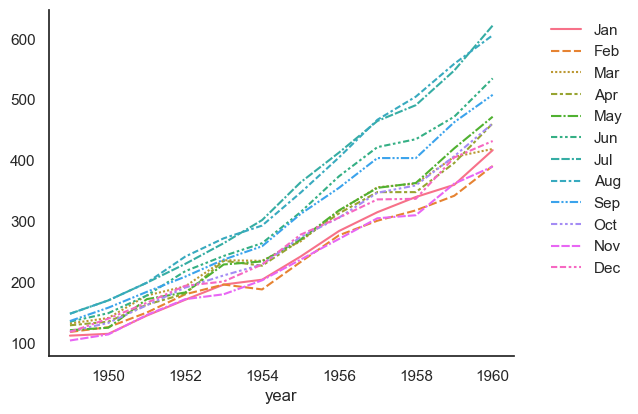

In [506]:
sns.lineplot(data=flights_wide);

sns.despine()
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', frameon=False);

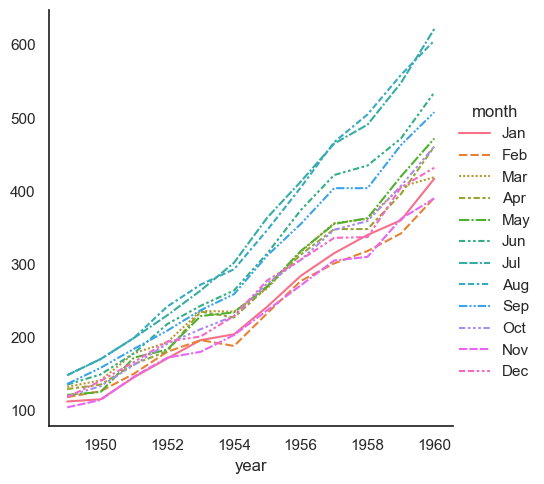

In [507]:
sns.relplot(data=flights_wide, kind="line");

When you want to examine effects across many levels of a variable, it can be a good idea to facet that variable on the columns and then “wrap” the facets into the rows:

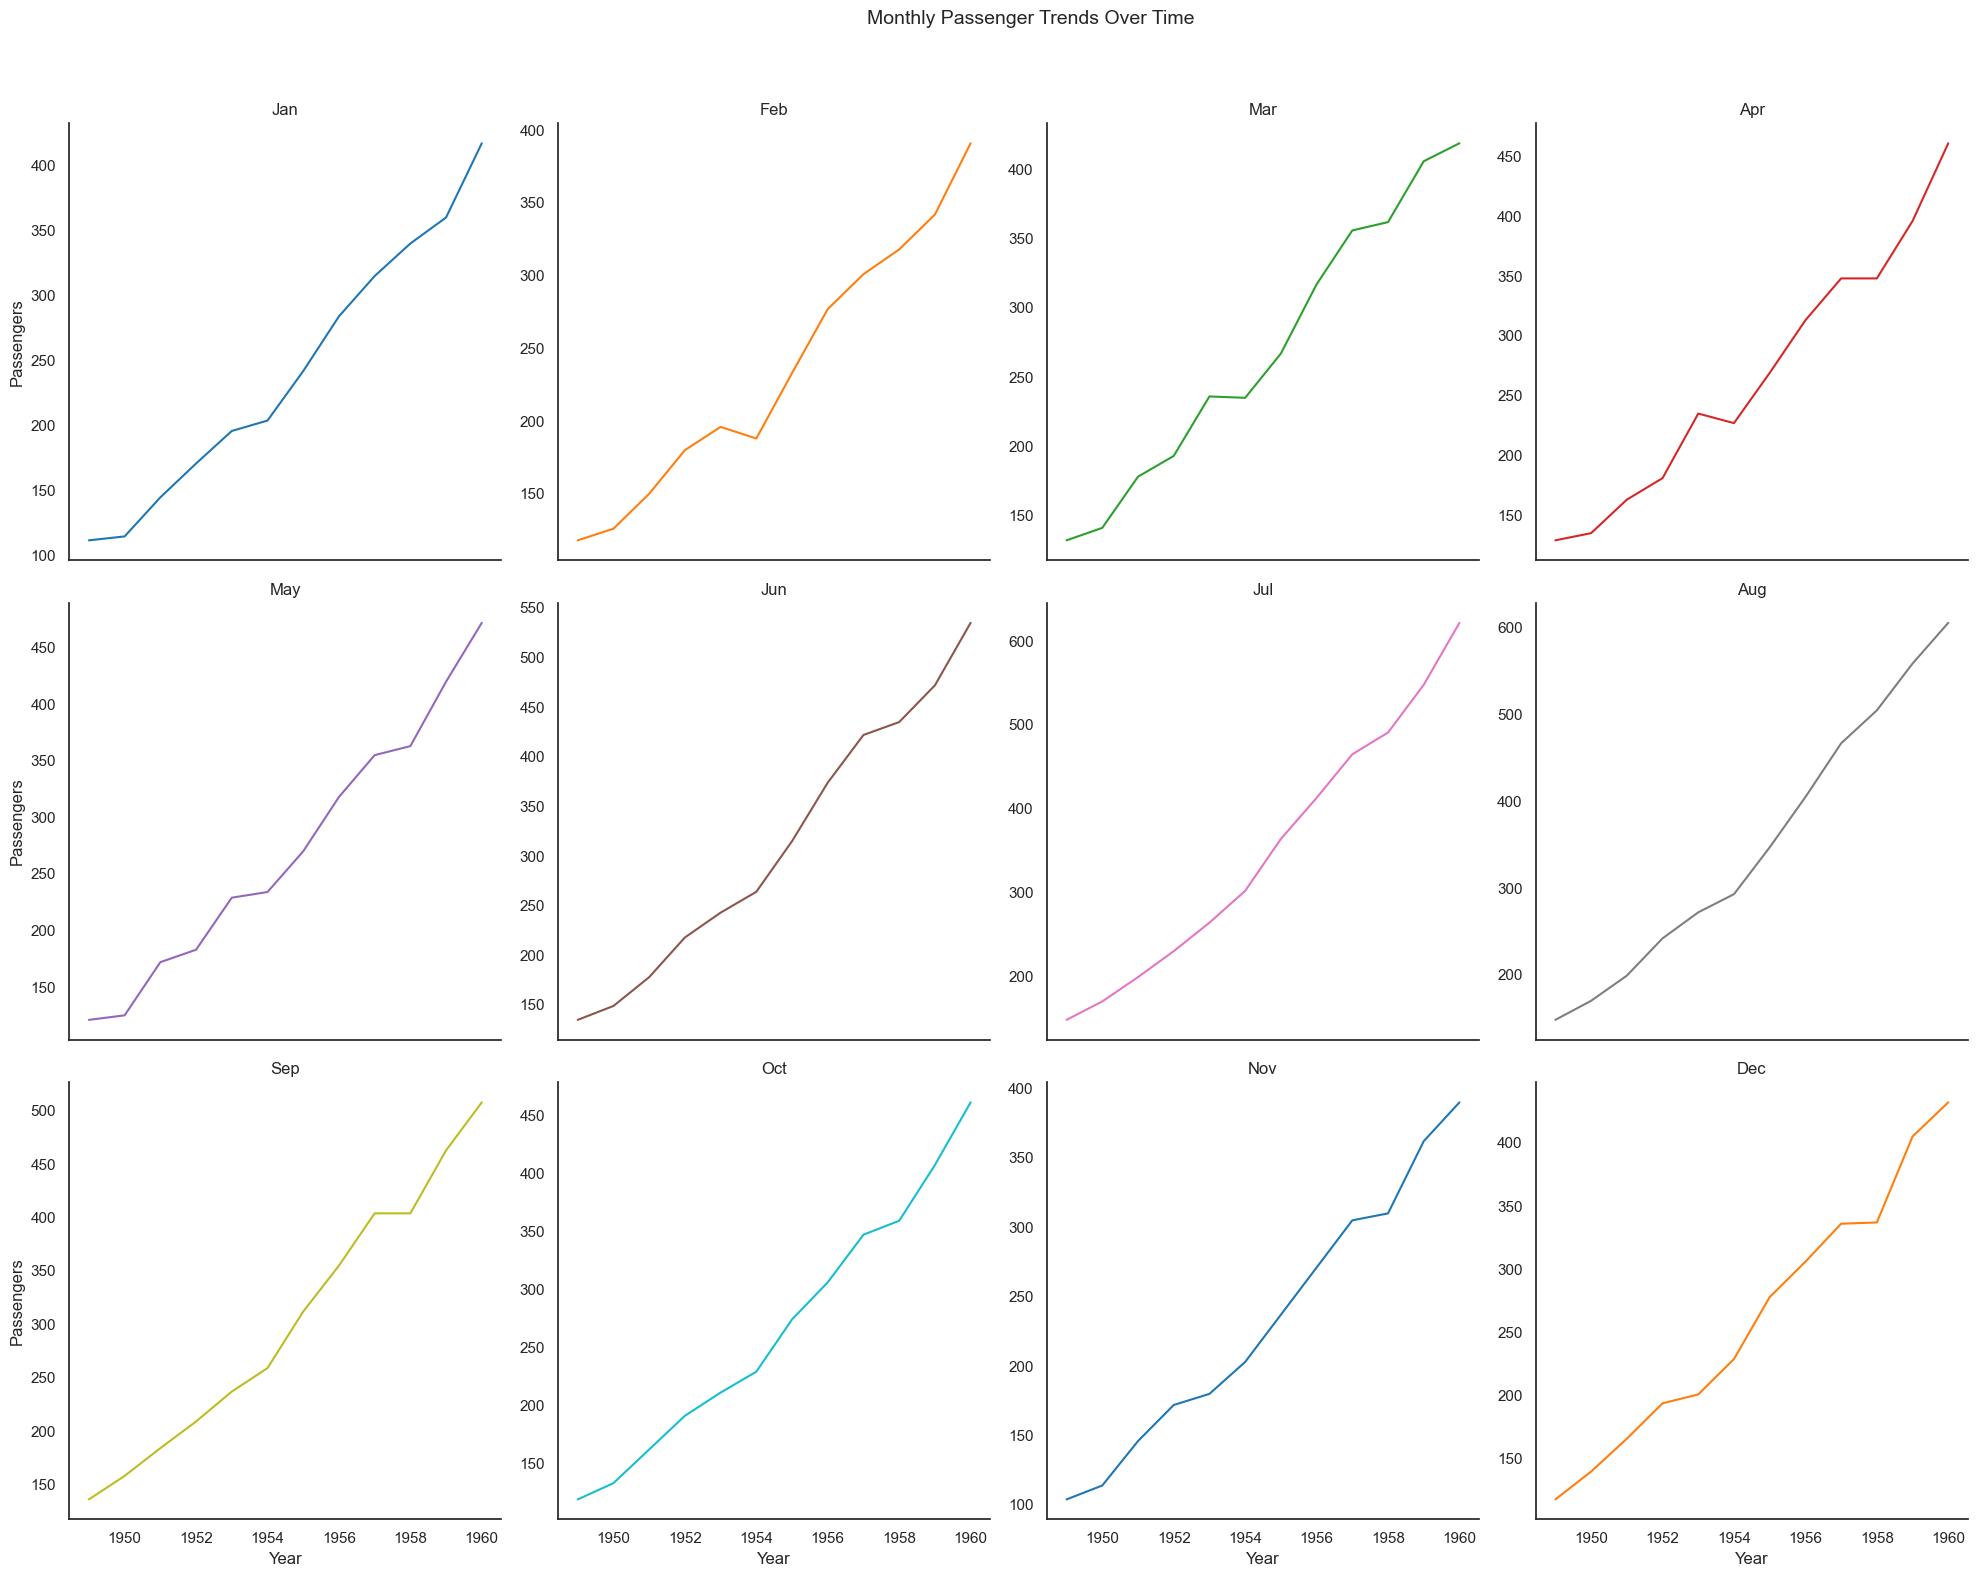

In [508]:
fig = sns.relplot(
    data=flights, 
    kind="line", 
    x="year", 
    y="passengers", 
    col="month", 
    hue="month", 
    col_wrap=4, 
    palette="tab10", 
    facet_kws={'sharey': False}  # Allows different y-scales per month if needed
)

fig._legend.remove()
fig.set_titles("{col_name}")  # Shows only month names as titles
fig.set_axis_labels("Year", "Passengers")  # Adds clear axis labels
fig.figure.suptitle("Monthly Passenger Trends Over Time", fontsize=14, y=1.05);  # Adds a main title

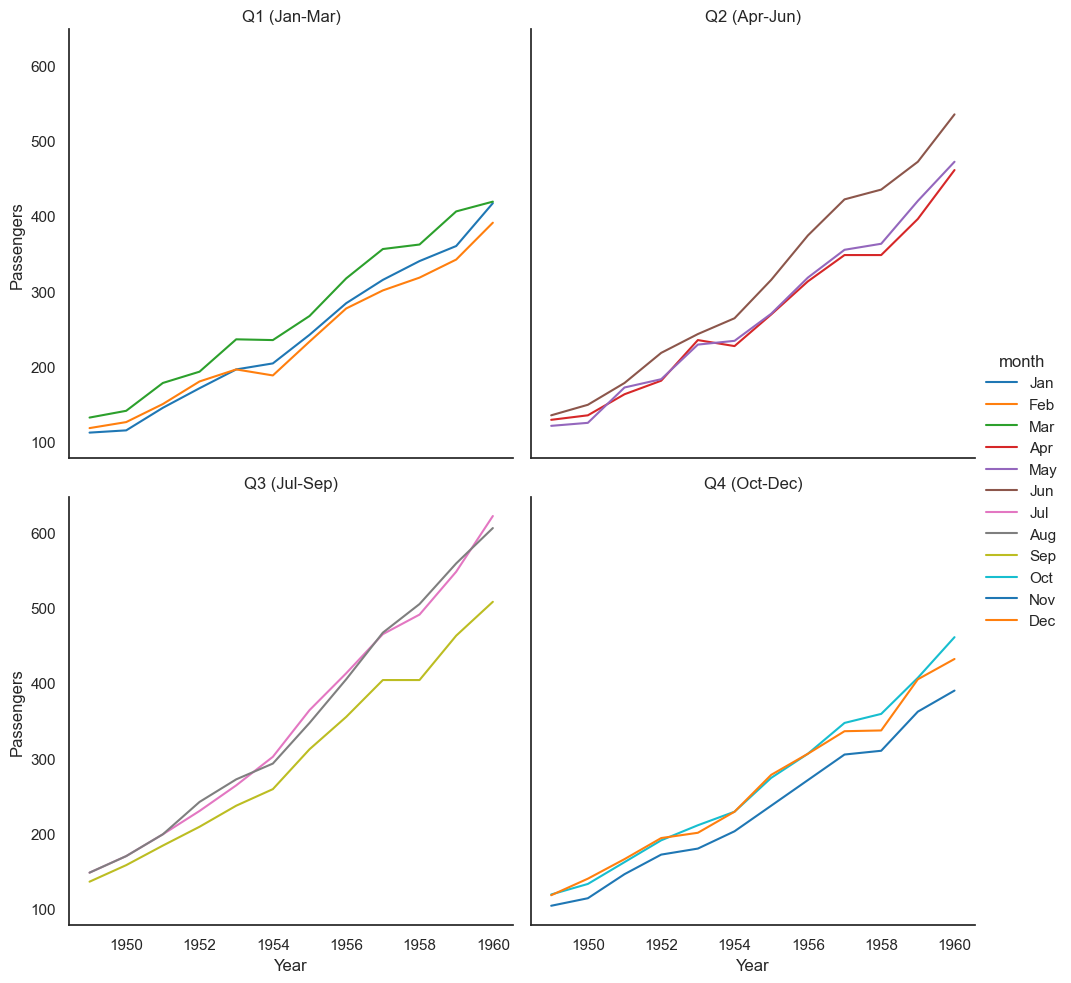

In [509]:
month_groups = {
    'Jan': 'Q1 (Jan-Mar)', 'Feb': 'Q1 (Jan-Mar)', 'Mar': 'Q1 (Jan-Mar)',
    'Apr': 'Q2 (Apr-Jun)', 'May': 'Q2 (Apr-Jun)', 'Jun': 'Q2 (Apr-Jun)',
    'Jul': 'Q3 (Jul-Sep)', 'Aug': 'Q3 (Jul-Sep)', 'Sep': 'Q3 (Jul-Sep)',
    'Oct': 'Q4 (Oct-Dec)', 'Nov': 'Q4 (Oct-Dec)', 'Dec': 'Q4 (Oct-Dec)'
}
flights['month_group'] = flights['month'].map(month_groups)

fig = sns.relplot(
    data=flights, 
    kind="line", 
    x="year", 
    y="passengers", 
    hue="month", 
    col="month_group", 
    col_wrap=2,
    palette="tab10"
)

fig.set_titles("{col_name}")
fig.set_axis_labels("Year", "Passengers");  

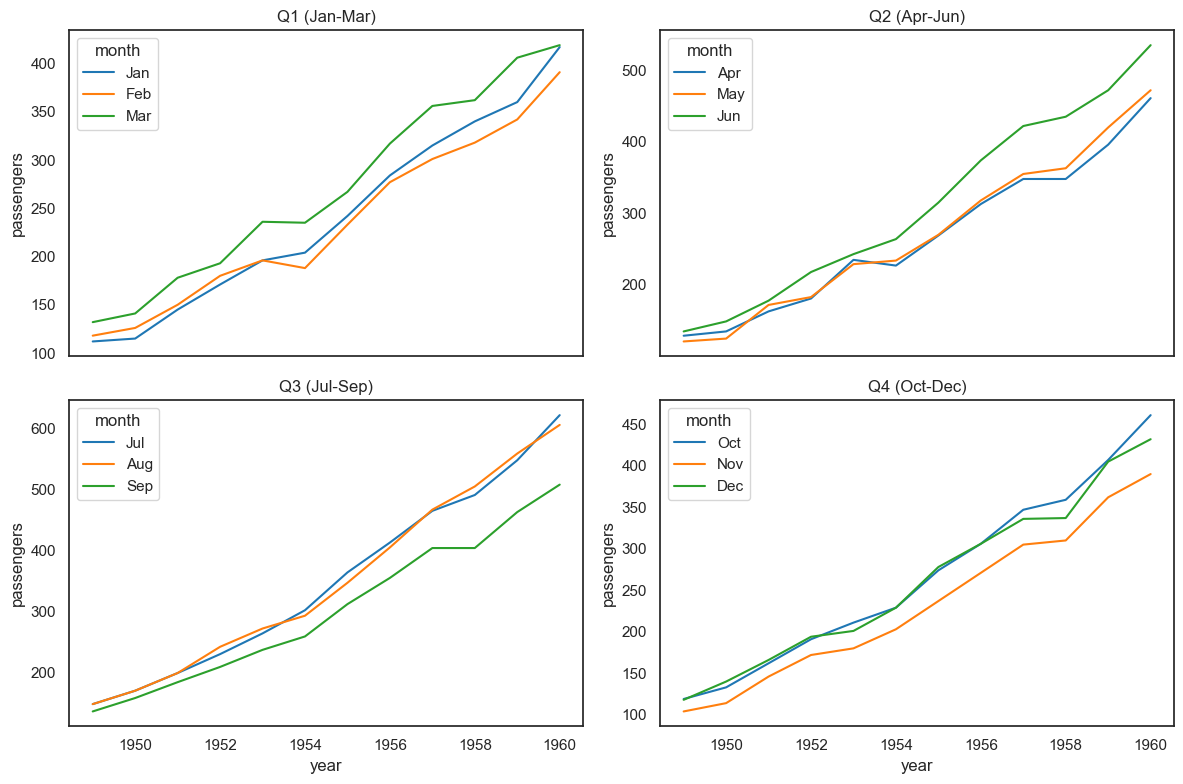

In [510]:
month_groups = [
    ['Jan', 'Feb', 'Mar'],  # Q1
    ['Apr', 'May', 'Jun'],  # Q2
    ['Jul', 'Aug', 'Sep'],  # Q3
    ['Oct', 'Nov', 'Dec']   # Q4
]
group_labels = ["Q1 (Jan-Mar)", "Q2 (Apr-Jun)", "Q3 (Jul-Sep)", "Q4 (Oct-Dec)"]


fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=False)
for ax, three_months, title in zip(axs.flatten(), month_groups, group_labels):
    subset = flights[flights['month'].isin(three_months)]
    
    # `hue_order` restricts the legend to current `three_months` in the subplot
    sns.lineplot(data=subset, x="year", y="passengers", hue="month", hue_order=three_months, palette="tab10", ax=ax)
    ax.set_title(title, fontsize=12)

plt.tight_layout() 

Passing the entire dataset in long-form mode will aggregate over repeated values along x axis (each year) to show the mean and 95% confidence interval:

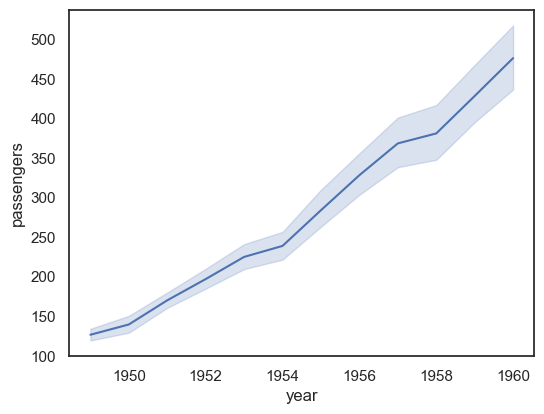

In [511]:
sns.lineplot(data=flights, x="year", y="passengers");

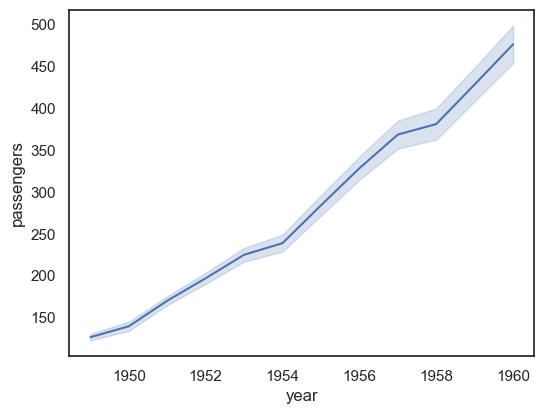

In [512]:
sns.lineplot(data=flights, x="year", y="passengers",errorbar="se");

### Available Options for `errorbar` in Seaborn

The `errorbar` parameter in `sns.relplot()` and `sns.lineplot()` controls how uncertainty is represented in line plots.

#### Standard Options

| Option | Meaning |
|--------|---------|
| `"se"` | Standard Error (default) |
| `"ci"` | Confidence Interval (default is 95%) |
| `"pi"` | Prediction Interval |


```python
sns.lineplot(data=fmri, x="timepoint", y="signal", errorbar="se")  # Standard Deviation Error (default: 1)
sns.lineplot(data=fmri, x="timepoint", y="signal", errorbar="ci")  # Confidence Interval (default: 95%)
sns.lineplot(data=fmri, x="timepoint", y="signal", errorbar="pi")  # Prediction Interval (default: 80%)
```



You can scale the error bars by a factor (default is **1**). This allows you to adjust the width of the error bars depending on the level of uncertainty you want to represent.

#### Available Scaling Options

| Option | Meaning |
|--------|---------|
| `("se", 2)` | 2 × Standard Error |
| `("ci", 90)` | 90% Confidence Interval |
| `("pi", 80)` | 80% Prediction Interval |


```python
sns.lineplot(data=fmri, x="timepoint", y="signal", errorbar=("se", 2))  # 2x Standard Error
sns.lineplot(data=fmri, x="timepoint", y="signal", errorbar=("se", 1.5))  # 1.5x Standard Error
```


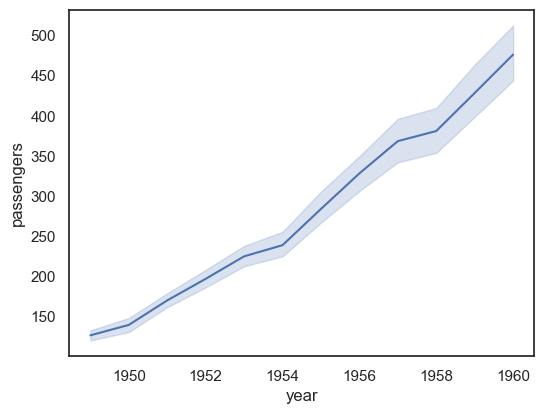

In [513]:
sns.lineplot(data=flights, x="year", y="passengers",errorbar=("ci", 90));

Use the `orient` parameter to aggregate and sort along the vertical dimension of the plot:

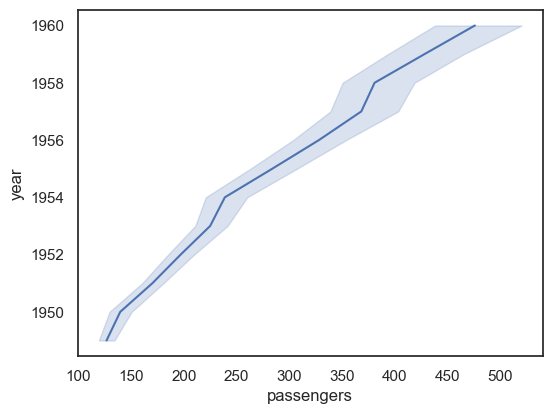

In [514]:
sns.lineplot(data=flights, x="passengers", y="year", orient="y");

Assign a grouping semantic (hue, size, or style) to plot separate lines:

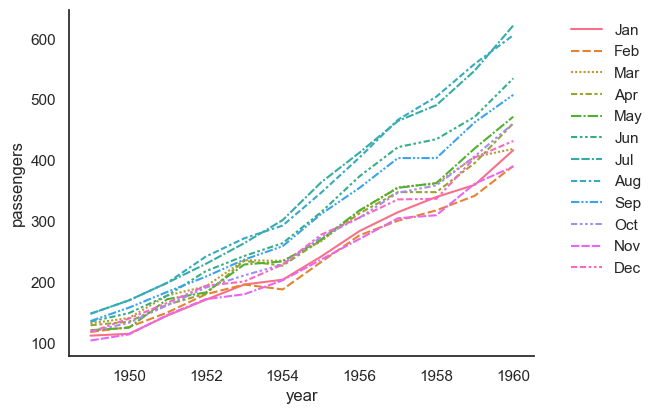

In [515]:
sns.lineplot(data=flights, x="year", y="passengers", hue="month", style="month")
sns.despine()
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', frameon=False);

Each semantic variable can also represent a different column. For that, we’ll need a more complex dataset:

In [516]:
fmri = sns.load_dataset("fmri")
fmri.sample(5)

,subject,timepoint,event,region,signal
784,s13,16,cue,frontal,-0.002522
443,s9,12,stim,frontal,-0.083663
100,s12,11,stim,parietal,-0.056628
732,s11,14,cue,frontal,0.050133
56,s0,15,stim,parietal,-0.053079


Repeated observations are aggregated:

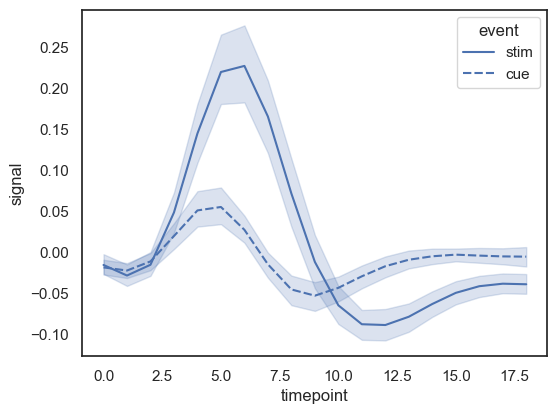

In [517]:
sns.lineplot(data=fmri, x="timepoint", y="signal", style="event"); # try: `hue`, `size`, `style`

When assigning a `style` variable, markers can be used instead of (or along with) dashes to distinguish the groups:

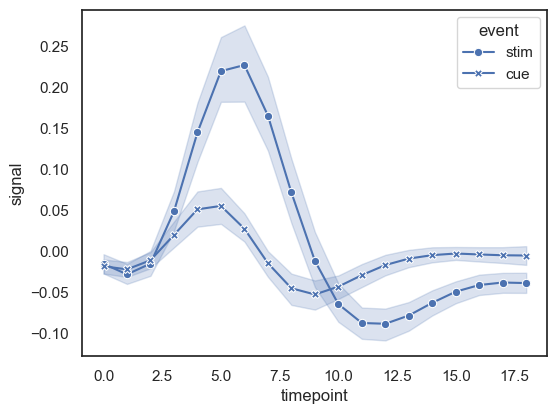

In [518]:
sns.lineplot(data=fmri, x="timepoint", y="signal", style="event", markers=True, dashes=False);

You can show error bars instead of error bands.

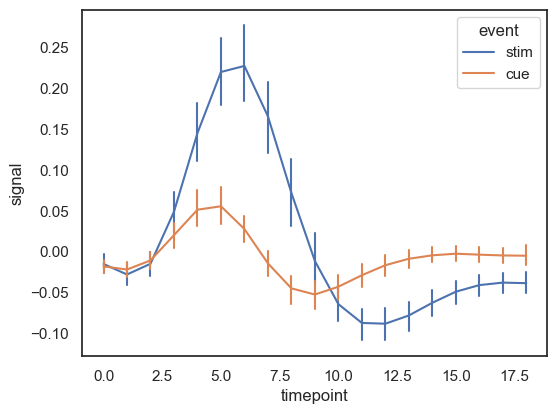

In [519]:
# sns.lineplot(data=fmri, x="timepoint", y="signal", hue="event", err_style="bars", errorbar=("se", 2));
# sns.lineplot(data=fmri, x="timepoint", y="signal", hue="event", err_style="bars", errorbar=("pi", 80));
sns.lineplot(data=fmri, x="timepoint", y="signal", hue="event", err_style="bars", errorbar=("ci", 95));


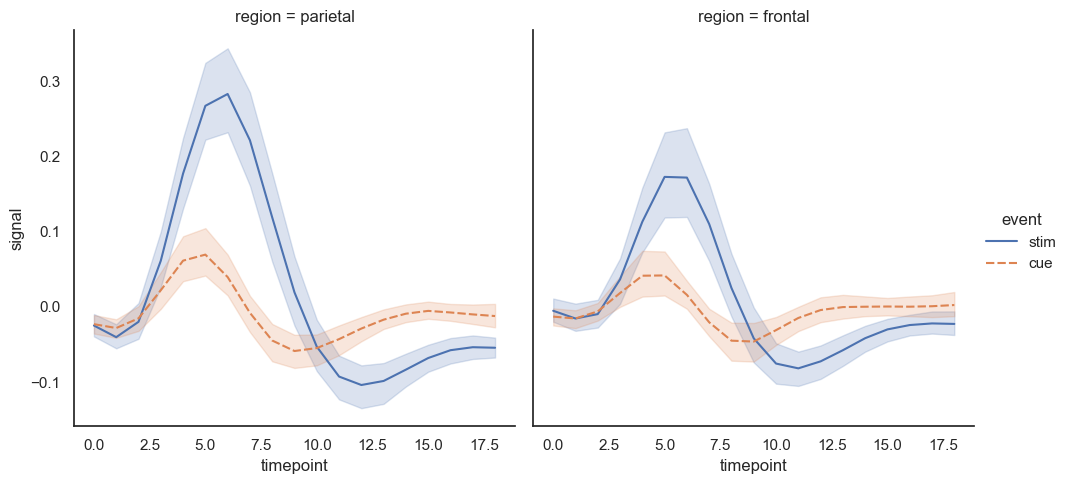

In [520]:
sns.relplot(
    data=fmri, x="timepoint", y="signal",
    col="region", hue="event", style="event",
    kind="line"
);

# Distribution plots

## `histplot`  and `displot`

A histogram is a classic visualization tool that represents the distribution of one or more variables by counting the number of observations that fall within discrete bins.

In [521]:
penguins = sns.load_dataset("penguins")
penguins.sample(4)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
131,Adelie,Torgersen,43.1,19.2,197.0,3500.0,Male
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
99,Adelie,Dream,43.2,18.5,192.0,4100.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


<Axes: xlabel='flipper_length_mm', ylabel='Count'>

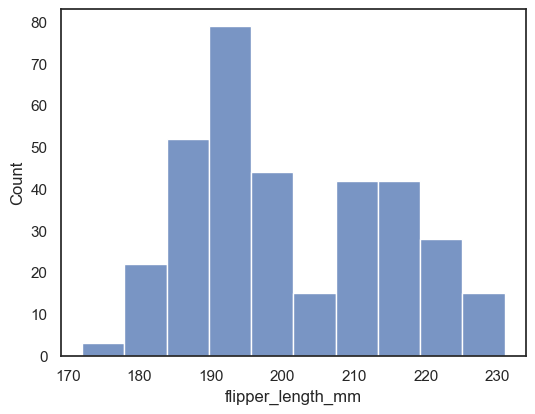

In [522]:
sns.histplot(data=penguins, x="flipper_length_mm")

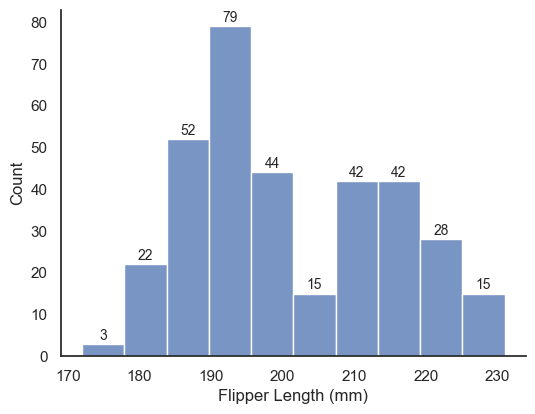

In [523]:
ax = sns.histplot(data=penguins, x="flipper_length_mm")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Count");
sns.despine()

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10, padding=1)


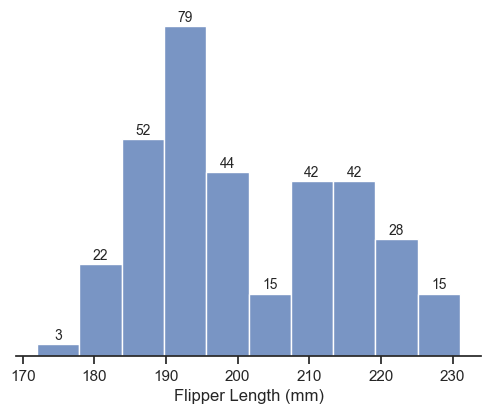

In [524]:
ax = sns.histplot(data=penguins, x="flipper_length_mm")
sns.despine(left=True)
ax.set(xlabel="Flipper Length (mm)", yticks=[], ylabel=None)
ax.tick_params(axis='x', which='major', bottom=True, top=False)
# `which` parameter determines which set of ticks ('major'/'minor'/'both') should be affected


# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10, padding=1)

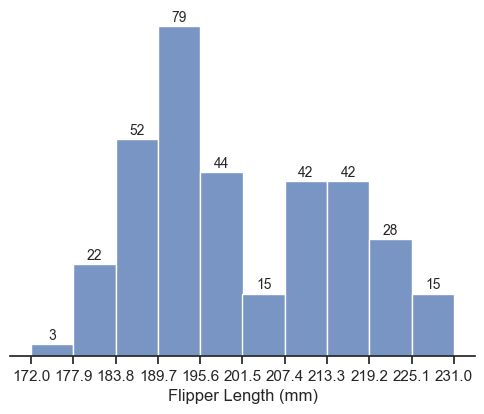

In [525]:
ax = sns.histplot(data=penguins, x="flipper_length_mm")
plt.xlabel("Flipper Length (mm)")
sns.despine(left=True)
ax.set(yticks=[], ylabel=None)
ax.tick_params(axis='x', which='major', bottom=True, top=False)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10, padding=1)


# Set x-axis ticks to match bin edges
bin_edges = ax.patches  # each bar in the histogram
bin_positions = [patch.get_x() for patch in bin_edges] 
bin_positions.append(bin_edges[-1].get_x() + bin_edges[-1].get_width())  # add the rightmost edge 
ax.set_xticks(bin_positions);

Flip the plot by assigning the data variable to the y axis:

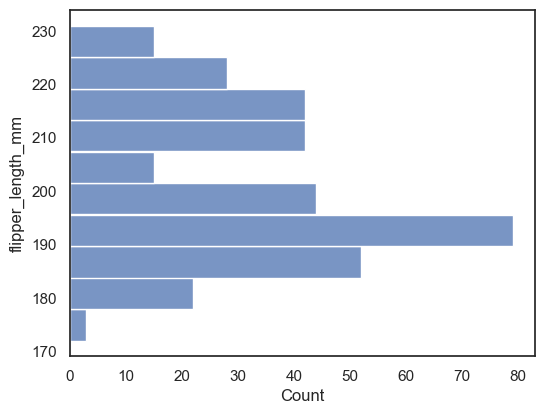

In [526]:
sns.histplot(data=penguins, y="flipper_length_mm");

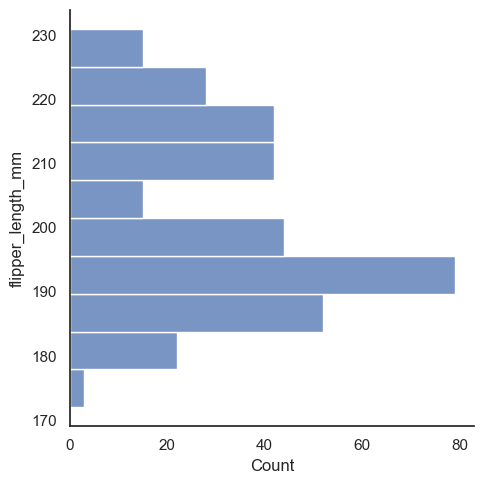

In [527]:
sns.displot(data=penguins, y="flipper_length_mm", kind='hist');

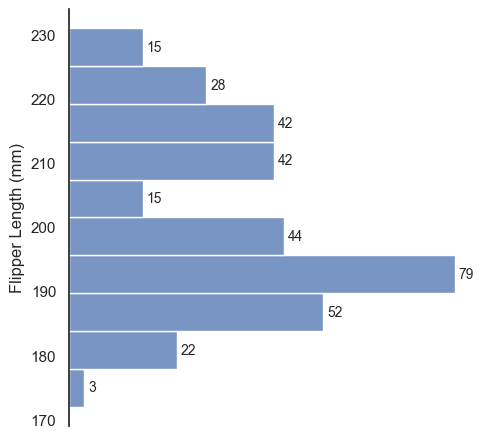

In [528]:
fig = sns.displot(data=penguins, y="flipper_length_mm", kind='hist')
sns.despine(bottom=True)
fig.set(xticks=[], xlabel=None, ylabel="Flipper Length (mm)")



# Add value labels on top of each bar
for ax in fig.axes.flat:  # iterate over FacetGrid axes
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', fontsize=10, padding=3)

You can specify:
- Bin width
- Number of bins

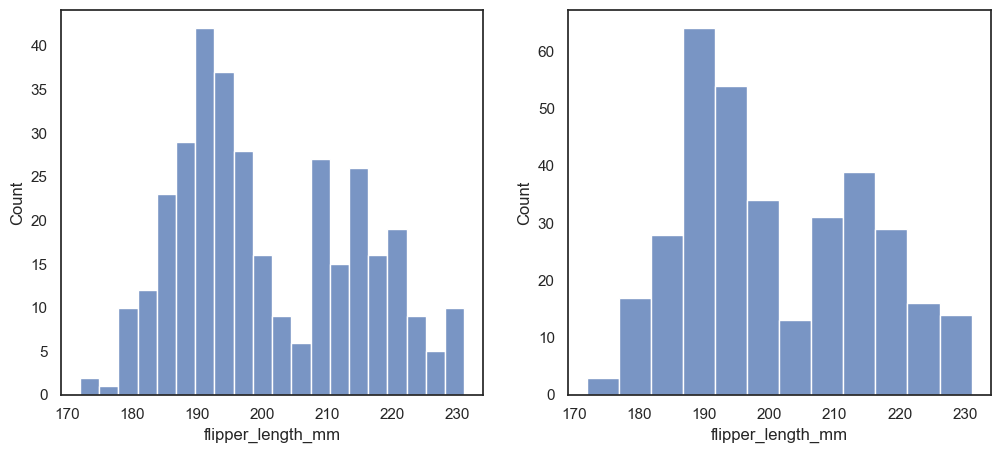

In [529]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))  

sns.histplot(data=penguins, x="flipper_length_mm", binwidth=3, ax=axs[0])
sns.histplot(data=penguins, x="flipper_length_mm", bins=12, ax=axs[1]);

You can add a kernel density estimate (KDE) of the distribution:

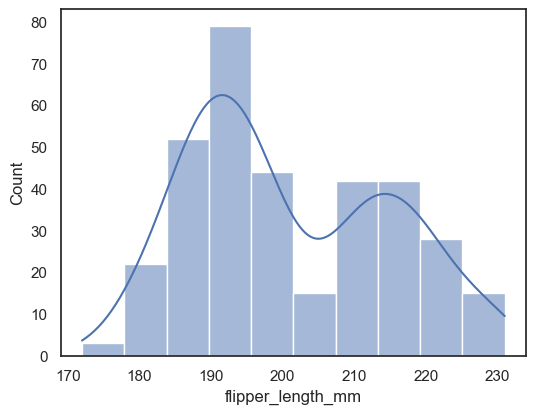

In [530]:
sns.histplot(data=penguins, x="flipper_length_mm", kde=True);

- You can plot multiple distributions *layering* them.

- *Layering* refers to overlaying multiple plots on the same axes to compare different distributions.

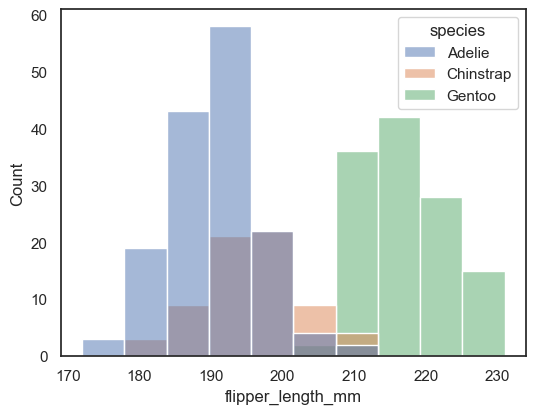

In [531]:
sns.histplot(data=penguins, x="flipper_length_mm", hue="species");

- An alternative would be to *stack* them.

- *Stacking* means placing plots on top of each other in separate subplots (above/below).

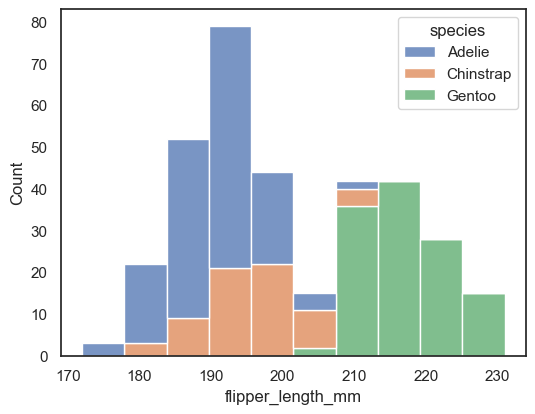

In [532]:
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", multiple="stack");

When using a `hue` semantic with discrete data, it can make sense to *dodge* the levels:

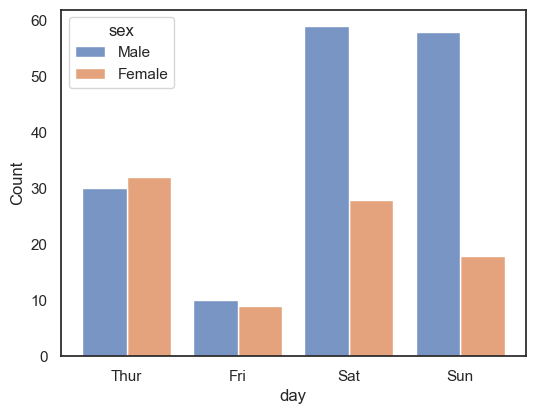

In [533]:
sns.histplot(data=tips, x="day", hue="sex", multiple="dodge", shrink=.8);

### Plotting disrete / categorical values with `sns.histplot`

In [534]:
tips = sns.load_dataset("tips")
tips.sample(3)

,total_bill,tip,sex,smoker,day,time,size
129,22.82,2.18,Male,No,Thur,Lunch,3
232,11.61,3.39,Male,No,Sat,Dinner,2
178,9.60,4.00,Female,Yes,Sun,Dinner,2


If we plot it as before, the default bin width may be too small, creating large gaps in the distribution.

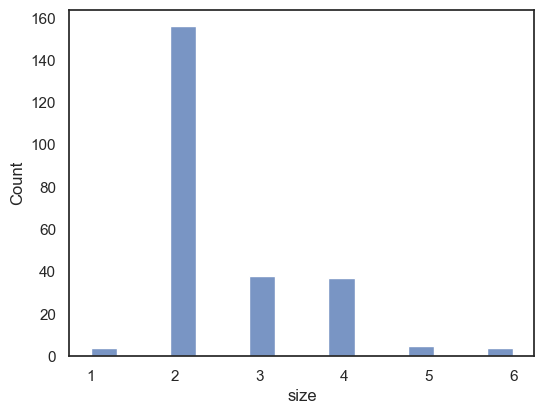

In [535]:
sns.histplot(data=tips, x="size");

You can restore the visual appeal by adjusting the following parameters:
- `discrete=True`
- `shrink=0.7`

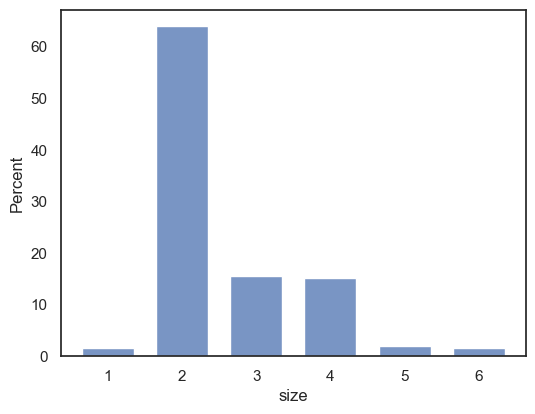

In [536]:
sns.histplot(data=tips, x="size", stat="percent", discrete=True, shrink=.7);

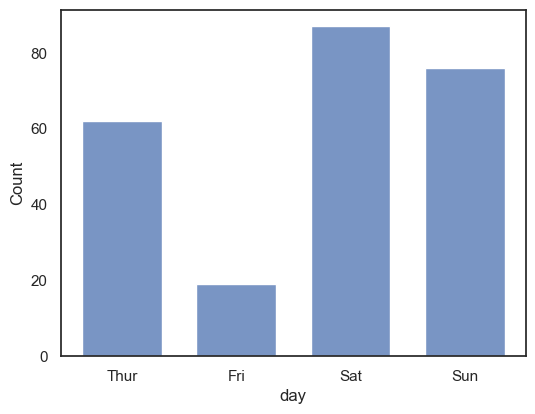

In [537]:
sns.histplot(data=tips, x="day", shrink=.7);

### Normalized histograms

You can normalize the counts using the `stat` parameter:
- `stat="count"` (default)
- `stat="percent"`
- `stat="probability"`
- `stat="density"`

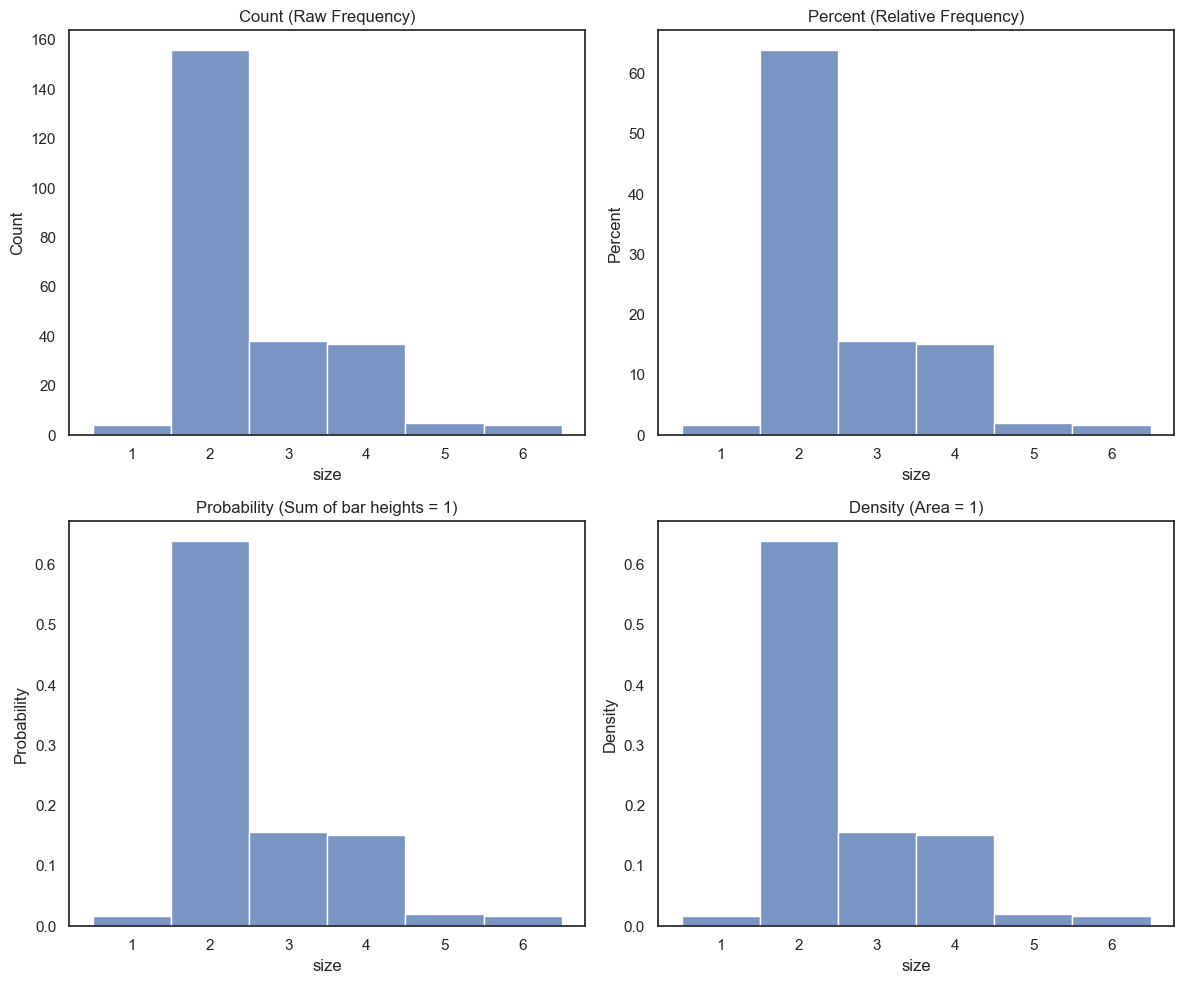

In [538]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Count (default)
sns.histplot(data=tips, x="size", stat="count", discrete=True, ax=axes[0, 0])
axes[0, 0].set_title("Count (Raw Frequency)")

# Percent
sns.histplot(data=tips, x="size", stat="percent", discrete=True, ax=axes[0, 1])
axes[0, 1].set_title("Percent (Relative Frequency)")

# Probability
sns.histplot(data=tips, x="size", stat="probability", discrete=True, ax=axes[1, 0])
axes[1, 0].set_title("Probability (Sum of bar heights = 1)")

# Density
sns.histplot(data=tips, x="size", stat="density", discrete=True, ax=axes[1, 1])
axes[1, 1].set_title("Density (Area = 1)")

# Adjust layout
plt.tight_layout()


When the subsets have unequal numbers of observations, comparing their distributions in terms of counts may not be ideal. One solution is to normalize the counts.

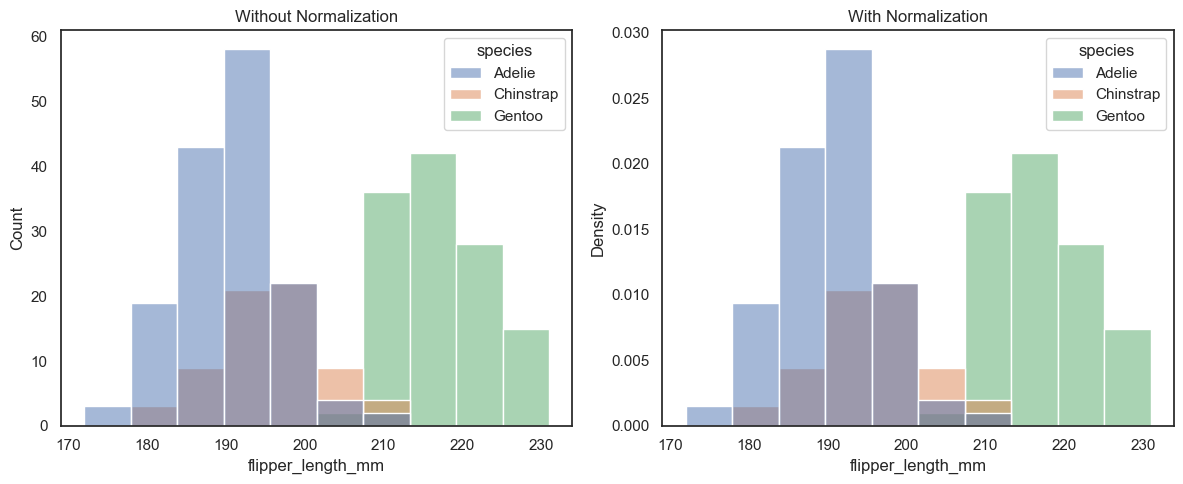

In [539]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=penguins, x="flipper_length_mm", hue="species", ax=axes[0])
axes[0].set_title("Without Normalization")

sns.histplot(data=penguins, x="flipper_length_mm", hue="species", stat="density", ax=axes[1])
axes[1].set_title("With Normalization")

plt.tight_layout()

By default, however, the normalization is applied to the entire distribution, so this simply rescales the height of the bars. By setting `common_norm=False`, each subset will be normalized independently. Useful for comparing distributions **without size bias**.

This option is particularly important when comparing multiple distributions, ensuring that the shape is emphasized rather than the relative frequency.

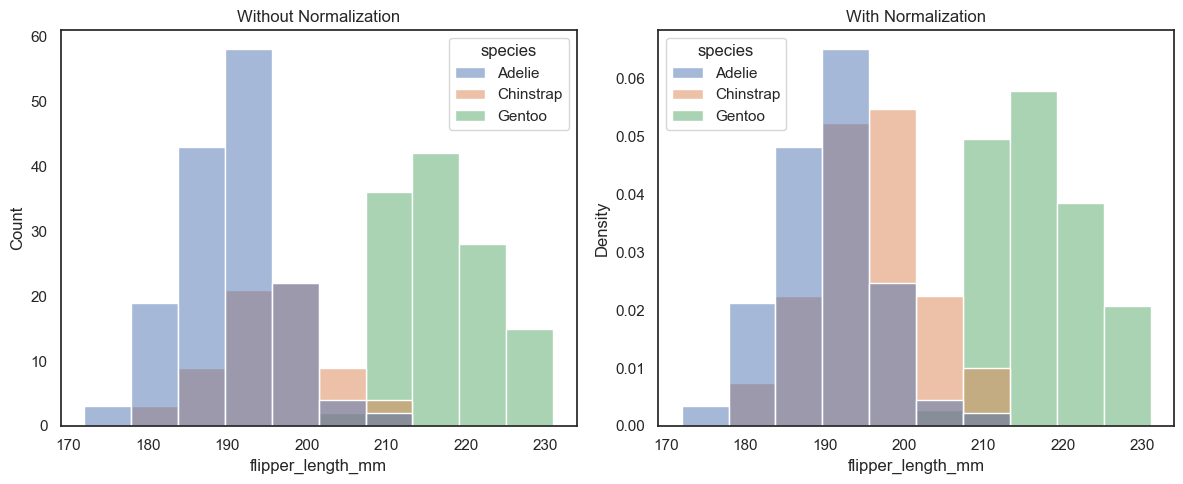

In [540]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=penguins, x="flipper_length_mm", hue="species", ax=axes[0])
axes[0].set_title("Without Normalization")

sns.histplot(data=penguins, x="flipper_length_mm", hue="species", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("With Normalization")

plt.tight_layout()

By default, the different histograms are “layered” on top of each other and, in some cases, they may be difficult to distinguish. One option is to change the visual representation of the histogram from a bar plot to a “step” plot.

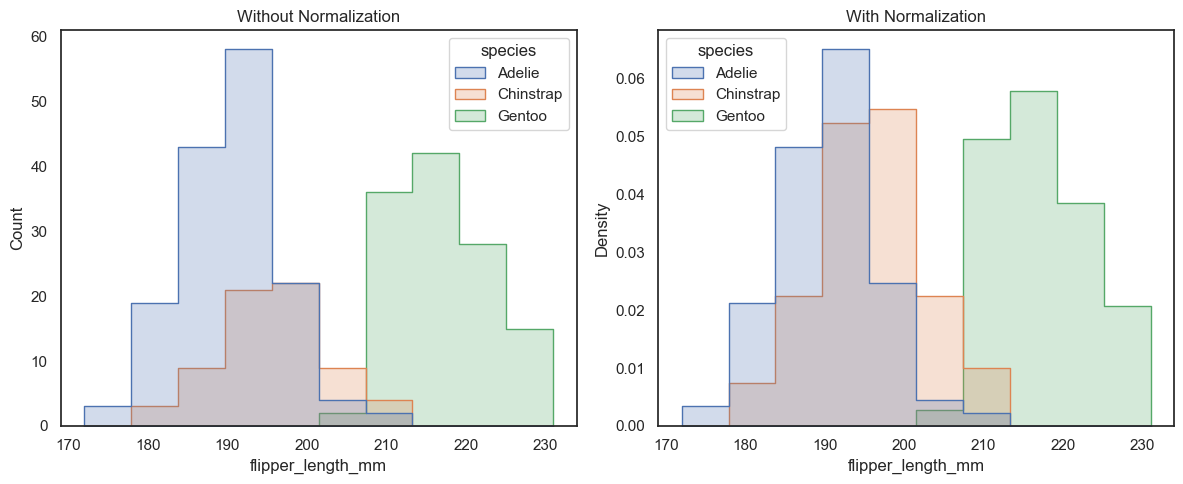

In [541]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=penguins, x="flipper_length_mm", hue="species", ax=axes[0],  element="step")
axes[0].set_title("Without Normalization")

sns.histplot(data=penguins, x="flipper_length_mm", hue="species", stat="density", common_norm=False, ax=axes[1],  element="step")
axes[1].set_title("With Normalization")

plt.tight_layout()

Real-world data is often skewed. For heavily skewed distributions, it’s better to define the bins in log space.

In [542]:
planets = sns.load_dataset("planets")
planets.sample(5)

,method,number,orbital_period,mass,distance,year
311,Radial Velocity,6,20.432000,0.0299,12.83,2008
921,Microlensing,2,1825.000000,NaN,NaN,2008
462,Radial Velocity,1,1951.000000,18.1500,57.21,2008
998,Transit,1,3.126088,NaN,NaN,2011
446,Radial Velocity,1,25.827000,0.1780,38.02,2004


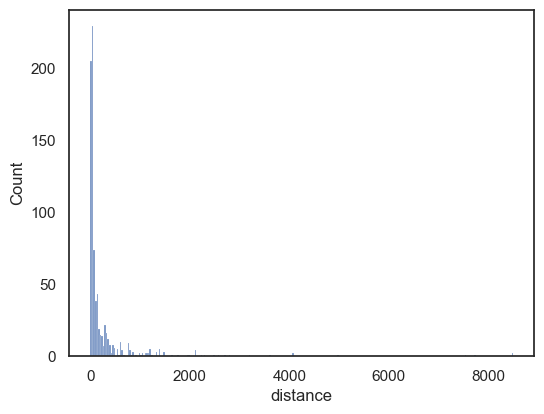

In [543]:
sns.histplot(data=planets, x="distance");

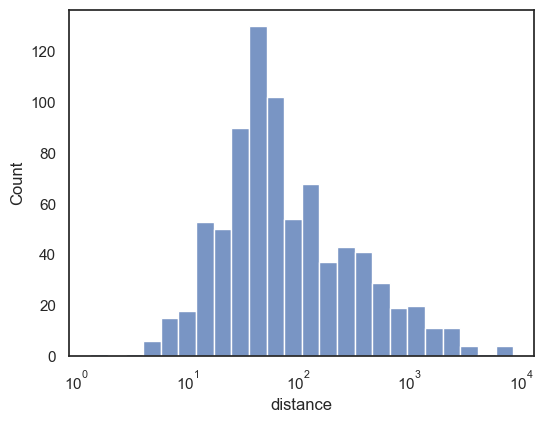

In [544]:
sns.histplot(data=planets, x="distance", log_scale=True);

### Bivariate histogram

When both x and y are assigned, a bivariate histogram is computed and shown as a heatmap.

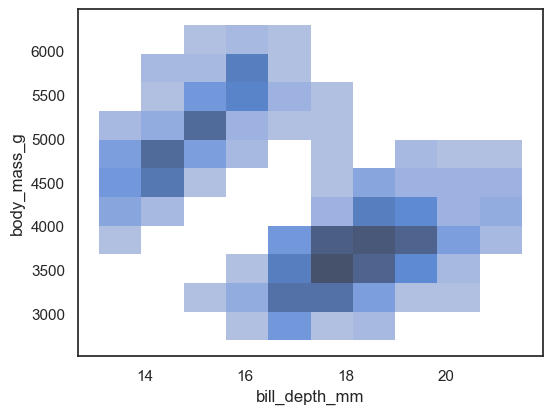

In [545]:
sns.histplot(penguins, x="bill_depth_mm", y="body_mass_g");

It accepts all of the same options for computation as its univariate counterpart, using tuples to parametrize x and y independently:

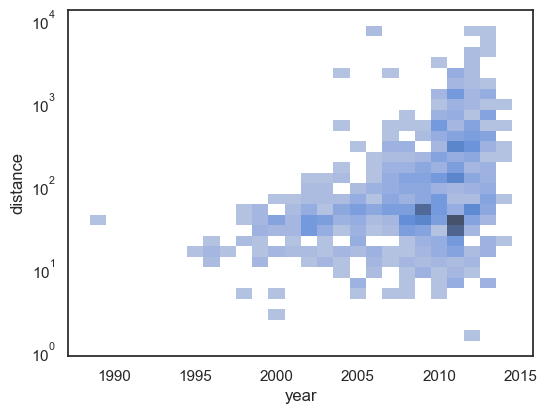

In [546]:
sns.histplot(
    planets, x="year", y="distance",
    bins=30, discrete=(True, False), log_scale=(False, True),
);

To annotate the colormap, add a colorbar:

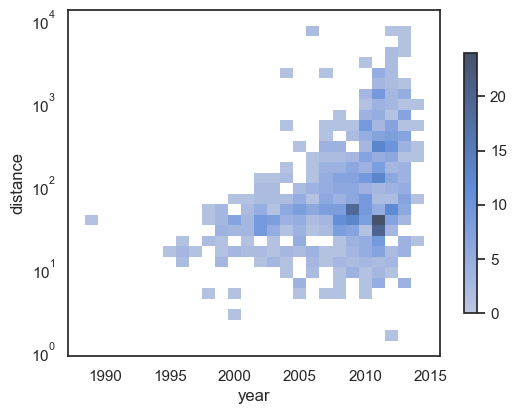

In [547]:
sns.histplot(
    planets, x="year", y="distance",
    bins=30, discrete=(True, False), log_scale=(False, True),
    cbar=True, cbar_kws=dict(shrink=.75),
);

## `kdeplot`  and `displot`


Kernel Density Estimation (KDE) is a non-parametric technique for estimating the probability density function (PDF) of a continuous variable. It smooths data points by placing a kernel (typically a Gaussian) over each observation and summing their contributions.

#### Key features:
- Provides a smooth estimate of the underlying distribution.
- Controlled by the **bandwidth** parameter, which determines the level of smoothing.
- Useful for visualizing distributions without relying on histograms.

#### Considerations:
- A **small bandwidth** captures fine details but may introduce noise.
- A **large bandwidth** results in excessive smoothing, potentially hiding patterns.
- KDE assumes a continuous variable and may not be very misleading for categorical data.

#### Parameters:
- `bw_adjust`
    - Controls the bandwidth of the kernel.
    - Affects the smoothness of the density curve.
    - Default is `bw_adjust=1`, meaning we use standard bandwidth determined by the data and kernel type.
        - Provides a balanced smoothness that works well in most cases.
    - **Higher values** increase smoothing (broader curve).
    - **Lower values** reduce smoothing (more sensitive to data variations).

- `cut`
    - Determines how far the KDE extends beyond the data range.
    - Default is `cut=3`, meaning the curve extends 3 bandwidths past the min/max.
    - **Higher values** extend the curve further, potentially introducing unrealistic tails.
    - **Lower values** restrict the range, limiting estimation outside the observed data.


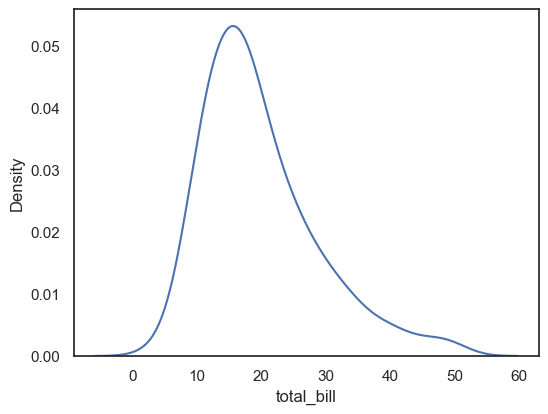

In [548]:
sns.kdeplot(data=tips, x="total_bill");
# sns.kdeplot(data=tips, y="total_bill")

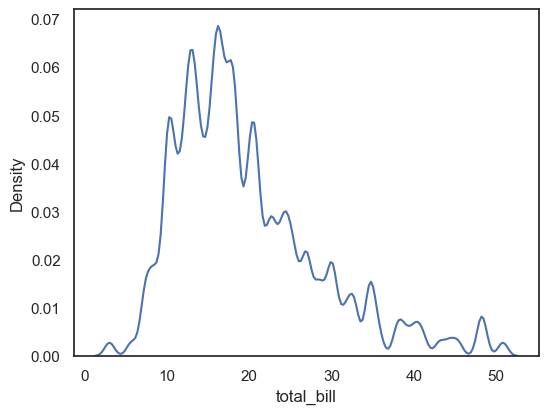

In [549]:
sns.kdeplot(data=tips, x="total_bill", bw_adjust=.2);

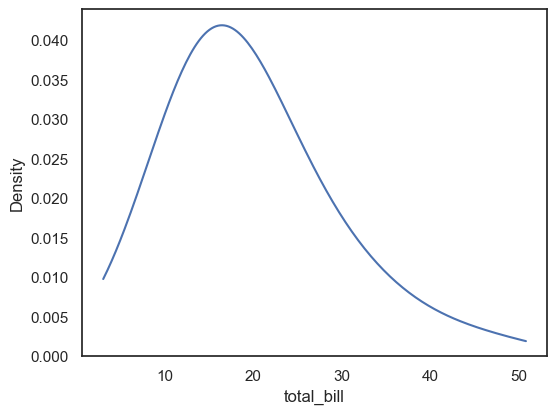

In [550]:
sns.kdeplot(data=tips, x="total_bill", bw_adjust=2, cut=0);

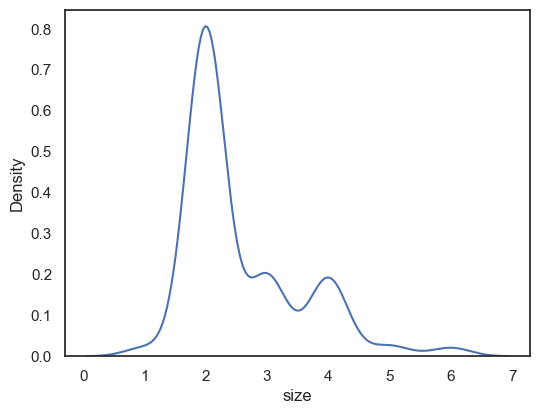

In [551]:
sns.kdeplot(data=tips, x="size");

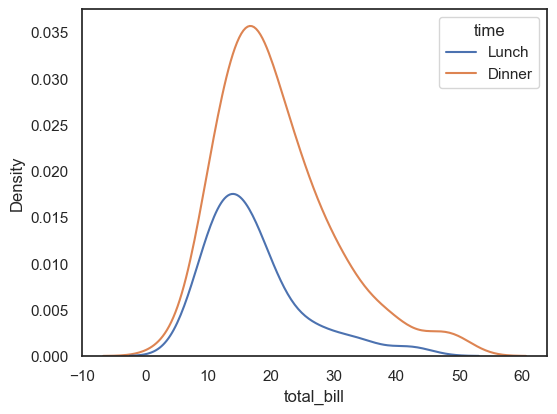

In [552]:
sns.kdeplot(data=tips, x="total_bill", hue="time");

We can modify the appearance:

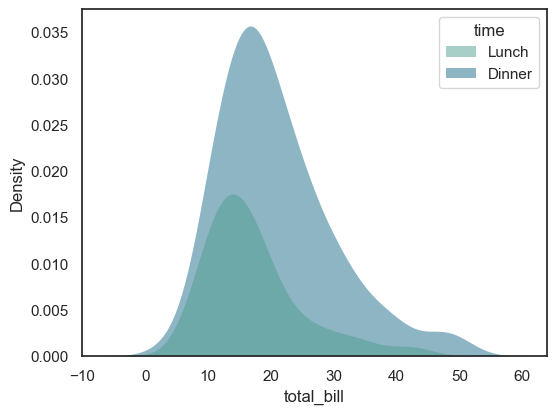

In [553]:
sns.kdeplot(
   data=tips, x="total_bill", hue="time",
   fill=True, common_norm=True, palette="crest",
   alpha=.5, linewidth=0
);

#### `palette` options

The `palette` parameter controls the color scheme used for different categories when `hue` is specified. 

#### Recommended Palettes for KDE:
1. **Sequential Palettes** (Best for ordered or numeric `hue` values like `size`)
   - `"crest"` (Smooth blue-green gradient)
   - `"mako"` (Dark-to-light blue)
   - `"viridis"` (Perceptually uniform, good for accessibility)
   - `"rocket"` (Dark red to light pink)

2. **Diverging Palettes** (For contrasting two groups)
   - `"coolwarm"` (Blue to red contrast)
   - `"RdBu"` (Red-blue gradient)
   - `"Spectral"` (Multi-hue divergence)

3. **Categorical Palettes** (For distinct categories)
   - `"deep"` (Default seaborn categorical colors)
   - `"Set1"`, `"Set2"`, `"Set3"` (Vivid categorical sets)
   - `"tab10"` (Matplotlib’s default categorical colors)

#### Choosing the Right Palette:
- Use **sequential palettes** for numerical order (`hue="size"` in your case).
- Use **categorical palettes** for distinct categories.
- Use **diverging palettes** when comparing two opposite trends.

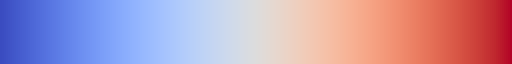

In [554]:
# To explore available palettes:
sns.color_palette("coolwarm", as_cmap=True)

- "under" – The color assigned to values **below** the normal data range (e.g., values below `vmin`).
- "bad" – The color used for **missing (`NaN`) or invalid** values.
- "over" – The color assigned to values **above** the normal data range (e.g., values above `vmax`).

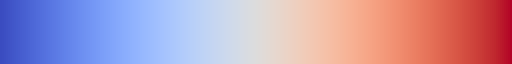

In [555]:
my_cmap = sns.color_palette("coolwarm", as_cmap=True)
my_cmap.set_bad("black")
my_cmap

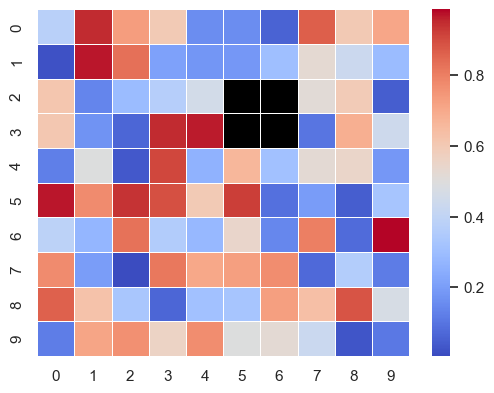

In [556]:

np.random.seed(42)
data = np.random.rand(10, 10)
data[2:4, 5:7] = np.nan  # we introduce NaN values

sns.heatmap(data, cmap=my_cmap, linewidths=0.5);

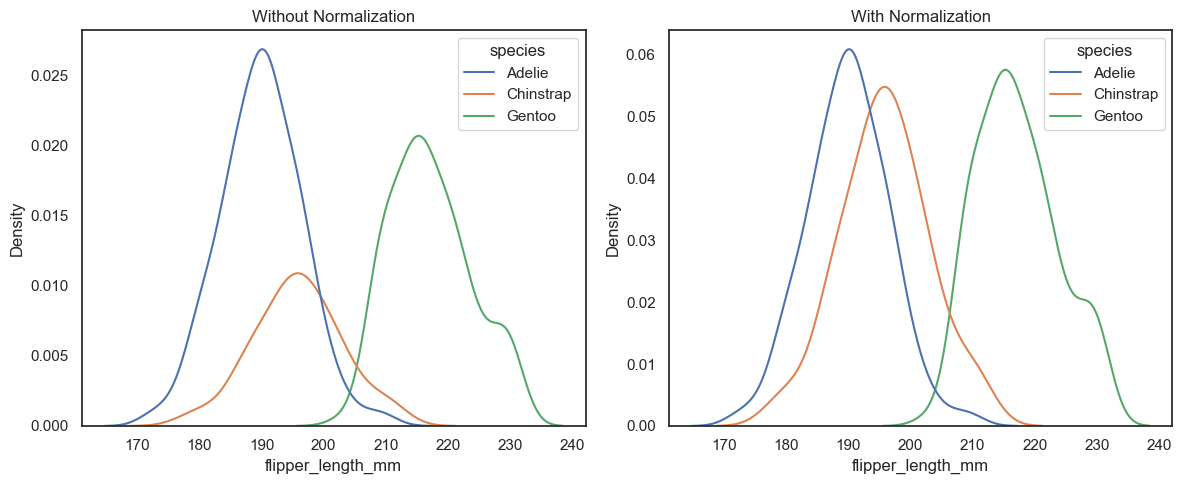

In [557]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.kdeplot(data=penguins, x="flipper_length_mm", hue="species", ax=axes[0])
axes[0].set_title("Without Normalization")

sns.kdeplot(data=penguins, x="flipper_length_mm", hue="species", common_norm=False, ax=axes[1])
axes[1].set_title("With Normalization")

plt.tight_layout()

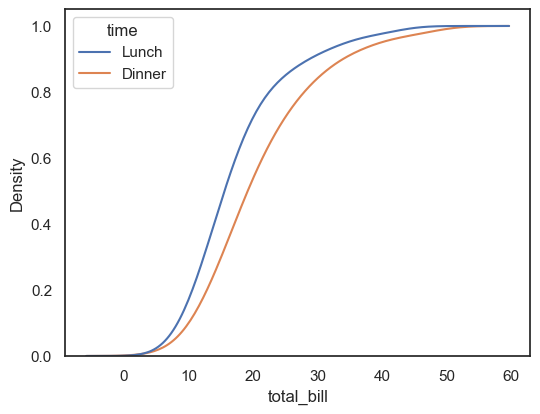

In [558]:
sns.kdeplot(
    data=tips, x="total_bill", hue="time",
    cumulative=True, common_norm=False, common_grid=True
);

### For a bivariative distribution

In [559]:
geyser = sns.load_dataset("geyser")
geyser.sample(5)

,duration,waiting,kind
114,1.700,59,short
4,4.533,85,long
237,4.283,77,long
57,1.667,64,short
72,4.500,79,long


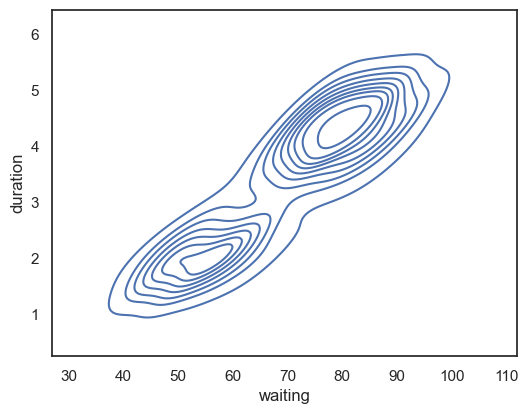

In [560]:
sns.kdeplot(data=geyser, x="waiting", y="duration");

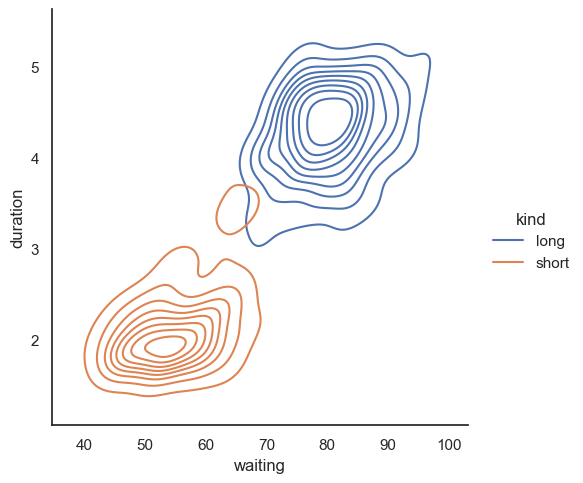

In [561]:
sns.displot(geyser, x="waiting", y="duration", hue="kind", kind='kde');

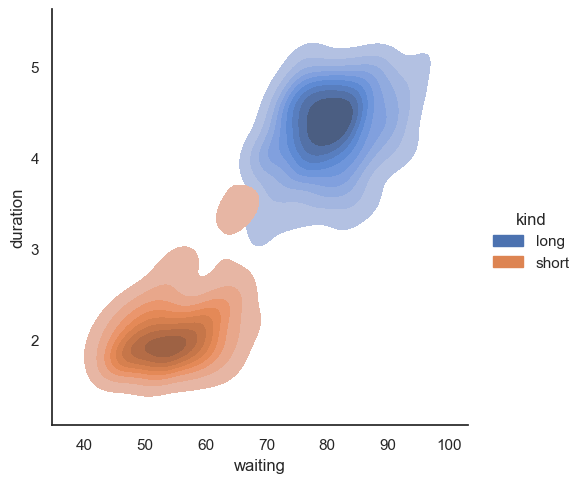

In [562]:
sns.displot(
    data=geyser, x="waiting", y="duration", hue="kind", fill=True, kind='kde'
);

## `ecdfplot`

#### Empirical Cumulative Distribution Function (ECDF) Plot

The `ecdfplot()` function in Seaborn visualizes the **empirical cumulative distribution function (ECDF)** of a dataset. Unlike histograms and KDE plots, which estimate density, an ECDF directly represents the proportion of data points that are **less than or equal to** a given value.

#### **Key Features:**
- Displays the cumulative proportion of observations.
- Provides a clear, non-smoothed view of the data distribution.
- Avoids binning artifacts present in histograms.
- Supports grouping with `hue` for categorical comparisons.

#### **When to Use:**
- To compare distributions without losing individual data points.
- When analyzing cumulative trends in numerical data.
- As an alternative to histograms and KDE plots for discrete or small datasets.

The ECDF is particularly useful for visualizing **percentiles** in an intuitive way.


In [563]:
penguins = sns.load_dataset("penguins")
penguins.sample(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
103,Adelie,Biscoe,37.8,20.0,190.0,4250.0,Male
33,Adelie,Dream,40.9,18.9,184.0,3900.0,Male
275,Gentoo,Biscoe,45.0,15.4,220.0,5050.0,Male
198,Chinstrap,Dream,50.1,17.9,190.0,3400.0,Female
192,Chinstrap,Dream,49.0,19.5,210.0,3950.0,Male


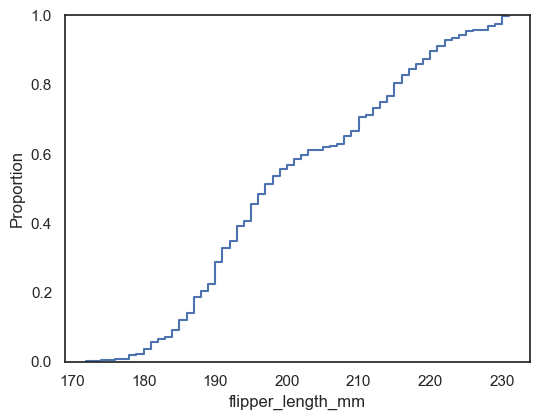

In [564]:
sns.ecdfplot(data=penguins, x="flipper_length_mm");

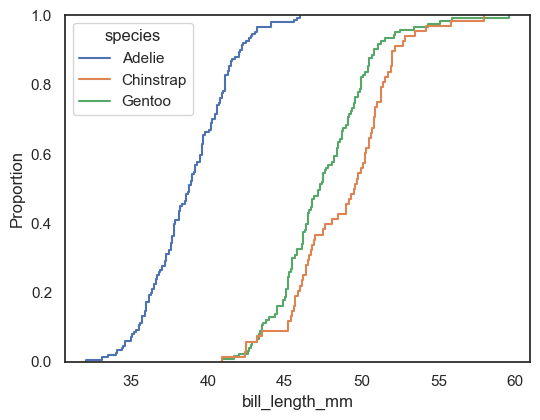

In [565]:
sns.ecdfplot(data=penguins, x="bill_length_mm", hue="species");

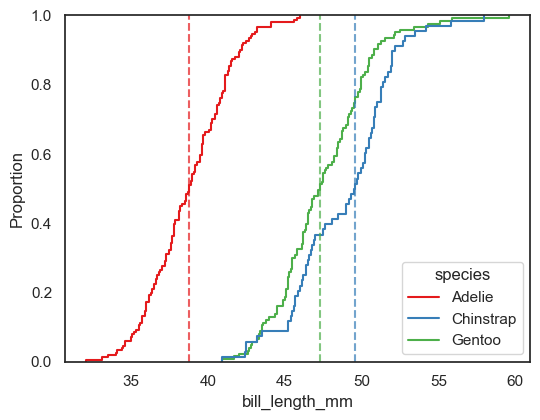

In [566]:
palette = sns.color_palette("Set1", n_colors=penguins["species"].nunique())
ax = sns.ecdfplot(data=penguins, x="bill_length_mm", hue="species", palette=palette)

medians = penguins.groupby("species")["bill_length_mm"].median()

# We map species to the corresponding colors from the palette
species_list = penguins["species"].unique()
species_colors = dict(zip(species_list, palette))  # match species to color

# Now we plot vertical dashed lines for medians with the correct colors
for species, median in medians.items():
    plt.axvline(median, linestyle="dashed", alpha=0.7, color=species_colors[species])


## `rugplot`

Provides a **marginal distribution visualization** by drawing small ticks (or "rugs") along an axis to represent individual data points.

### Rug in 1D

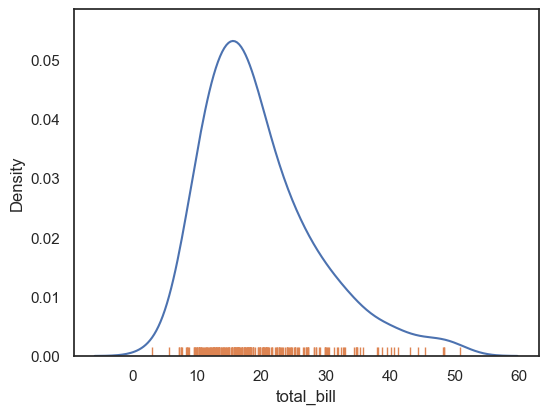

In [569]:
sns.kdeplot(data=tips, x="total_bill")
sns.rugplot(data=tips, x="total_bill");

### Rug in 2D

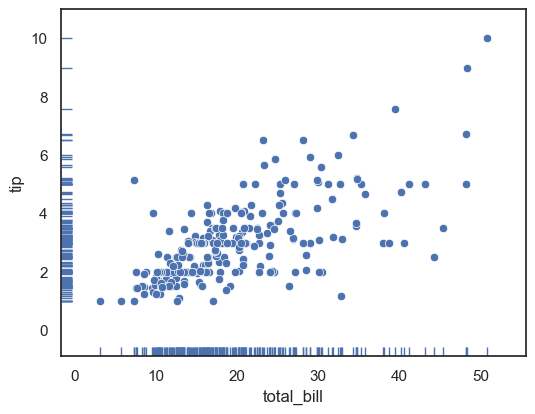

In [571]:
sns.scatterplot(data=tips, x="total_bill", y="tip")
sns.rugplot(data=tips, x="total_bill", y="tip");

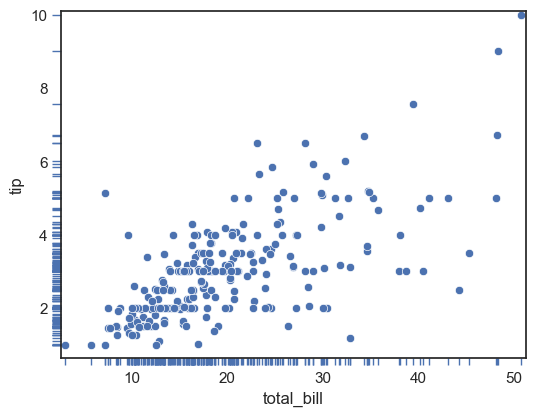

In [573]:
sns.scatterplot(data=tips, x="total_bill", y="tip")
sns.rugplot(data=tips, x="total_bill", y="tip", height=-.02, clip_on=False);

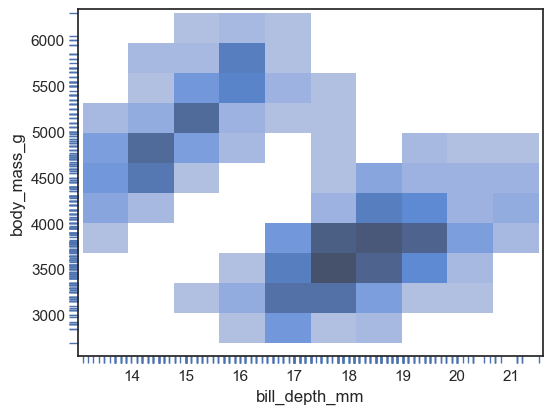

In [574]:
sns.histplot(penguins, x="bill_depth_mm", y="body_mass_g")
sns.rugplot(penguins, x="bill_depth_mm", y="body_mass_g", height=-.02, clip_on=False);

## `stripplot` and `catplot`

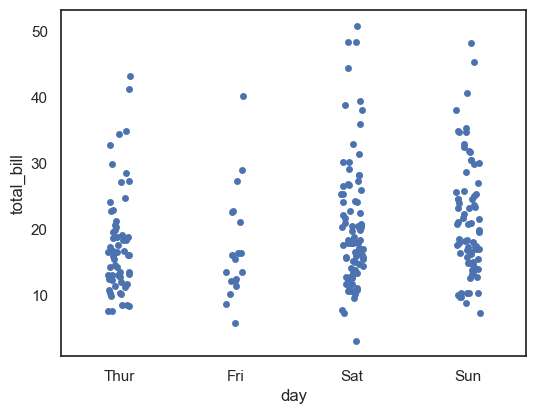

In [576]:
sns.stripplot(data=tips, x="day", y="total_bill");

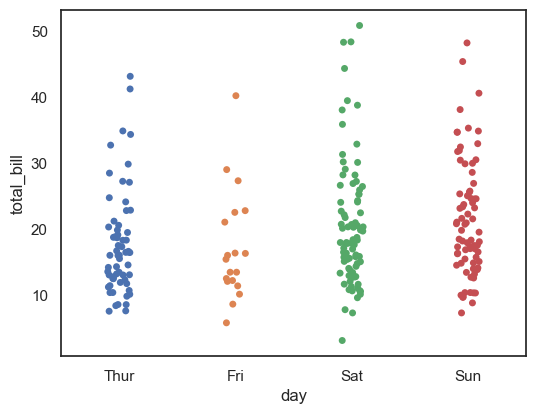

In [580]:
sns.stripplot(data=tips, x="day", y="total_bill", hue="day", legend=False);

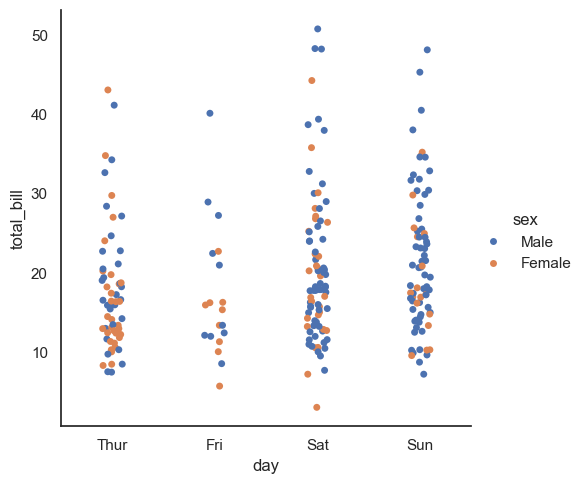

In [582]:
sns.catplot(data=tips, y="total_bill", x="day", hue="sex");

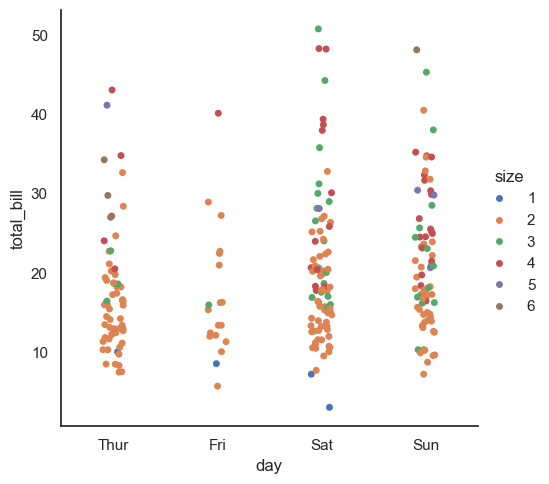

In [585]:
sns.catplot(data=tips, y="total_bill", x="day", hue="size", palette="deep");

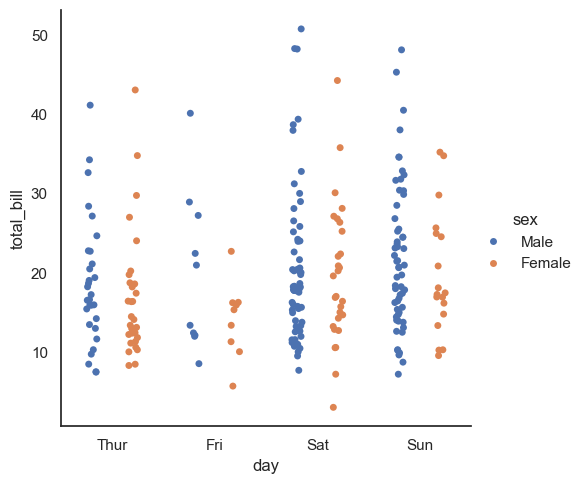

In [588]:
sns.catplot(data=tips, y="total_bill", x="day", hue="sex", dodge=True);

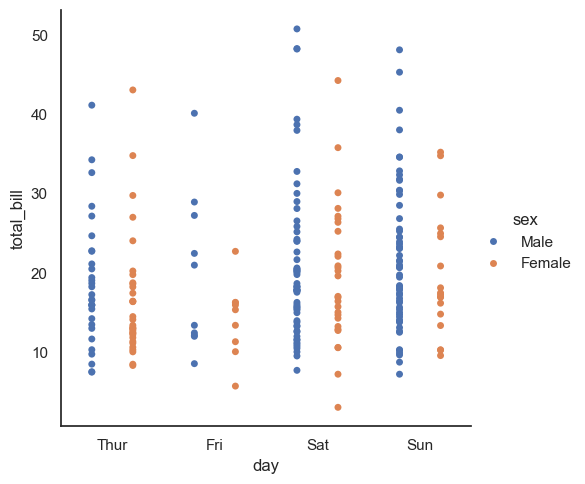

In [590]:
sns.catplot(data=tips, y="total_bill", x="day", hue="sex", dodge=True, jitter=False);

We can play with it:

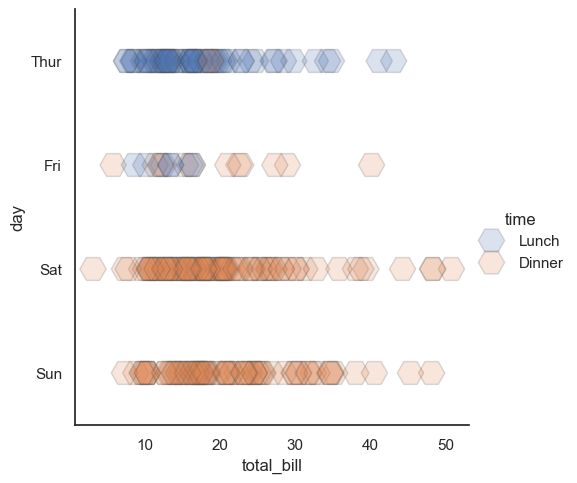

In [603]:
sns.catplot(
    data=tips, x="total_bill", y="day", hue="time",
    jitter=False, s=360, marker="H", linewidth=1, alpha=.2,
);

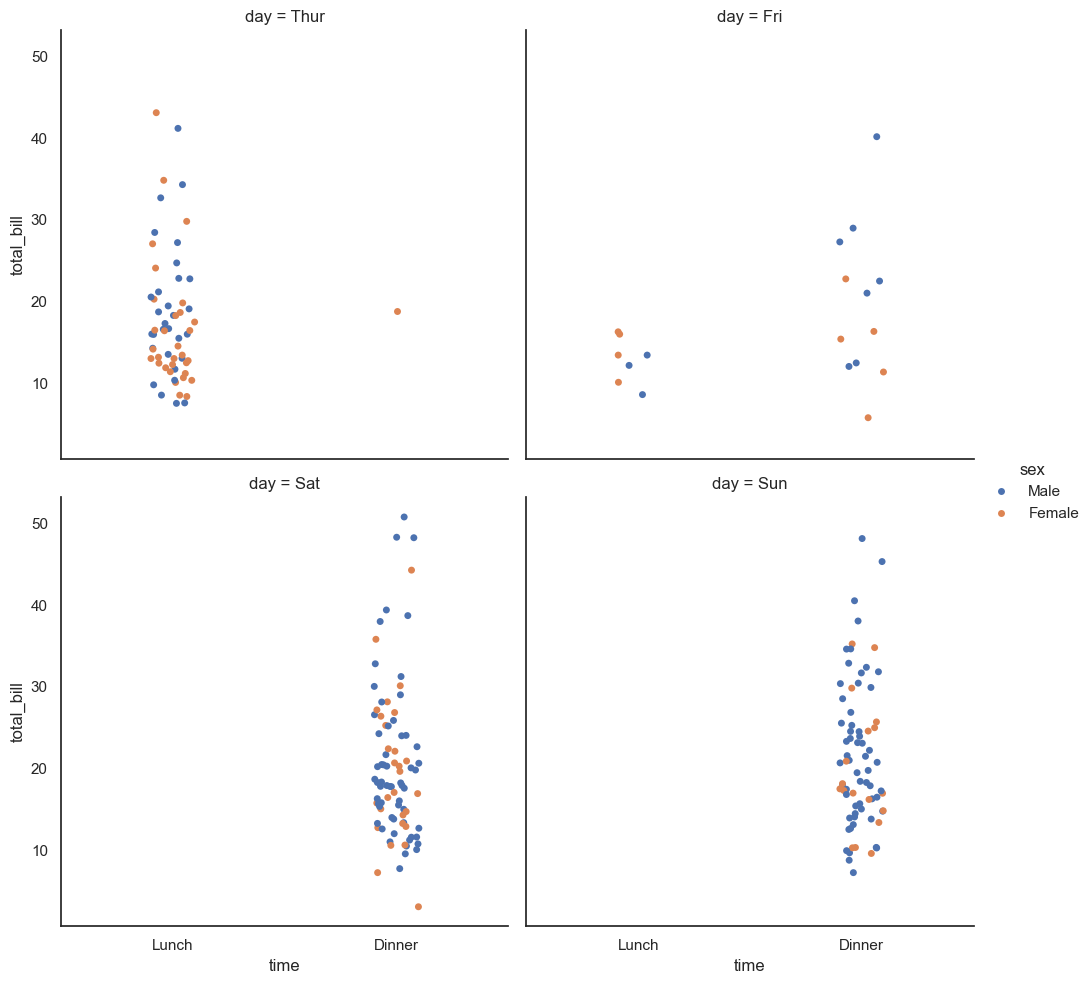

In [613]:
sns.catplot(data=tips, x="time", y="total_bill", hue="sex", col="day", col_wrap=2);

## `violinplot`

Violinplot represents a distribution two ways: a patch showing a symmetric kernel density estimate (KDE), and the quartiles / whiskers of a box plot.

In [614]:
df = sns.load_dataset("titanic")
df.sample(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
624,0,3,male,21.0,0,0,16.1000,S,Third,man,True,NaN,Southampton,no,True
448,1,3,female,5.0,2,1,19.2583,C,Third,child,False,NaN,Cherbourg,yes,False
341,1,1,female,24.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False
512,1,1,male,36.0,0,0,26.2875,S,First,man,True,E,Southampton,yes,True
362,0,3,female,45.0,0,1,14.4542,C,Third,woman,False,NaN,Cherbourg,no,False


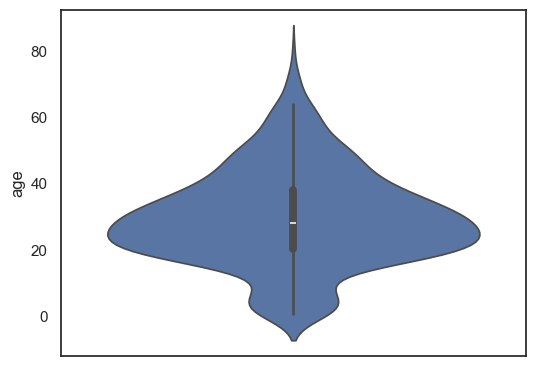

In [617]:
sns.violinplot(y=df["age"]);

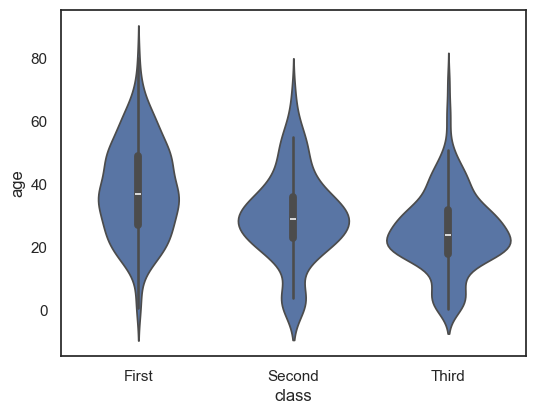

In [619]:
sns.violinplot(data=df, y="age", x="class");

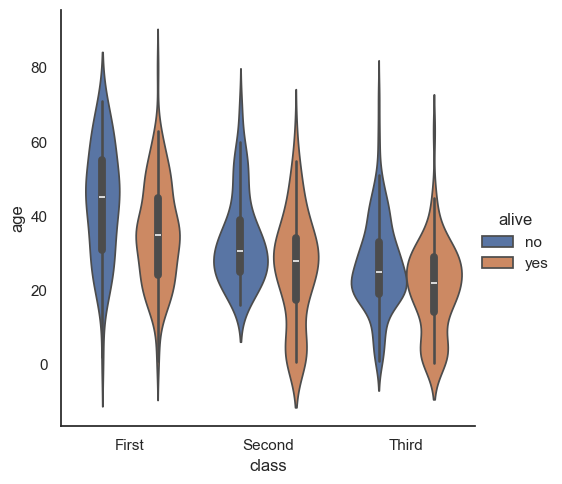

In [622]:
sns.catplot(data=df, x="class", y="age", hue="alive", kind="violin");

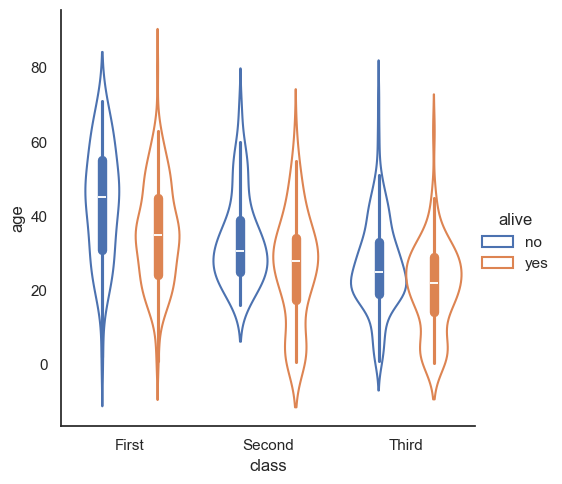

In [624]:
sns.catplot(data=df, x="class", y="age", hue="alive", fill=False, kind="violin");

Draw “split” violins to take up less space, and only show the data quarties.

Best works when `hue` is binary.

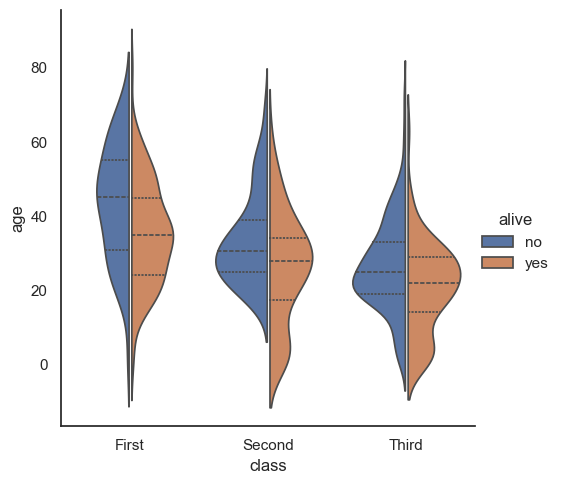

In [646]:
sns.catplot(data=df, x="class", y="age", hue="alive", gap=.05, split=True, inner="quart", kind="violin");

The `inner` parameter in **violin plots** controls the appearance of **data points** inside each violin. It determines what is displayed within the distribution shape.

#### Available `inner` Options:
- **`"box"`** – Displays a **miniature boxplot** inside each violin (default).
- **`"quart"`** – Draws horizontal lines at the **quartiles (25th, 50th, and 75th percentiles)**.
- **`"point"`** – Shows individual **data points** inside the violin.
- **`"stick"`** – Displays **vertical lines** for each observation.
- **`None`** – Removes any internal markings, leaving only the violin shape.

#### How `inner` Affects the Plot
- **`"quart"`** (used in your example) highlights **central tendencies** without overwhelming the visualization.
- **`"box"`** adds a **boxplot** for better statistical insights.
- **`"point"`** or `"stick"` can be useful for **smaller datasets** to show individual values.

#### Best Use Cases
- **`"box"`** – When comparing distributions **with summary statistics**.
- **`"quart"`** – When emphasizing **percentiles and medians**.
- **`"point"` / `"stick"`** – When dealing with **small datasets** to show actual observations.
- **`None`** – When focusing **only on density distribution**.



By default, the “inner” representation scales with the linewidth and linecolor parameters.

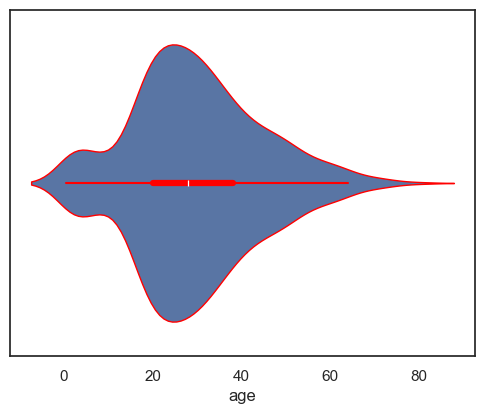

In [638]:
sns.violinplot(data=df, x="age", linewidth=1, linecolor="red");

Use inner_kws to pass parameters directly to the inner plotting functions.

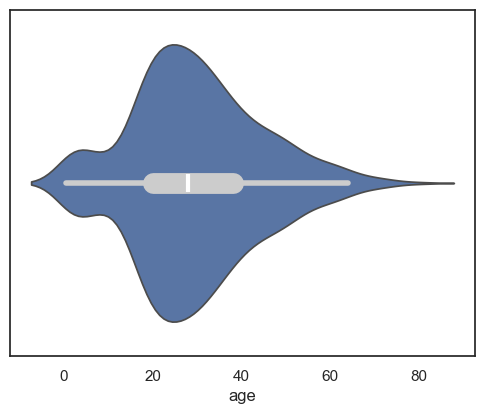

In [642]:
sns.violinplot(data=df, x="age", inner_kws=dict(box_width=15, whis_width=4, color=".8"));
# `whis_width` parameter controls the width of the whisker caps